[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QGAN_RealDeviceIntrusionDetection_Cirillo2025.ipynb)

# Hybrid quantum GAN for intrusion detection on (emulated) IBM devices: Cirillo and Esposito 2025 step by step

**Paper.** Franco Cirillo and Christian Esposito, *Quantum Generative Adversarial Networks for Intrusion Detection: An Experimentation on Real Quantum Devices*, 2025 IEEE International Conference on Quantum Artificial Intelligence (QAI), pp. 381-386. DOI: [10.1109/QAI63978.2025.00065](https://doi.org/10.1109/QAI63978.2025.00065). (The notebook is written from the paper text only; no author code was used.)

**What this notebook does.** The paper trains a very small *quantum GAN* on the **benign** traffic of NSL-KDD: the generator is a 4-qubit circuit (RY encoding of a random latent vector followed by a trainable `EfficientSU2` ansatz of depth 4), the discriminator is a small classical network. The paper's point is hardware: training on a real IBM device (IBM Sherbrooke) is too expensive, so the authors train on the noisy emulator `FakeSherbrooke` and swap **one epoch on the real device after every nine emulator epochs** (a *hybrid* run, 90 epochs), and compare it with a run of 220 epochs entirely on the emulator. They report that the Frechet distance (FID) of the generated samples falls in both runs, that the discriminator's accuracy reaches about 0.88 in both, and that the two runs hardly differ.

There is no quantum computer here, so the notebook does the next best thing and says so everywhere:

* the **ideal** generator is simulated exactly (state vector);
* the **noisy** generator is simulated *exactly* too, as a density matrix, for the circuit that Qiskit compiles for `FakeSherbrooke` (native gates `rz, sx, x, ecr`, routing on the heavy-hex coupling map) with the noise model of that fake backend (gate errors, thermal relaxation, read-out error). The simulator is a small PyTorch program so that it is differentiable (the training needs gradients), and a cell asserts that it gives the same probabilities as Qiskit Aer's density-matrix simulator;
* the **hybrid** run uses the noisy simulator for nine epochs out of ten. The tenth epoch is the "real device" epoch. **Without an IBM token it is only a stand-in** (the noisy simulator sampled with a finite number of shots); with `IBM_TOKEN` set, the cells of Section 7 sample the generator on the real device instead. The numbers the paper obtained on the real Sherbrooke device are therefore *the paper's values to compare against*, not something this notebook reproduces.

Because the paper has no detection scores, the notebook adds (clearly marked as an extra) what the trained discriminators and classical detectors do as anomaly detectors on the same four features.

**How to run it.** Open it in Google Colab (a CPU runtime is enough), choose *Runtime -> Run all*. `FAST_MODE = True` is a quick demo that finishes in about 10 minutes (60 / 40 epochs, 100 samples per epoch, one seed). `FAST_MODE = False` uses the paper's epoch counts (220 / 90) with 300 samples per epoch, three seeds for the cheap runs and the entanglement ablation; it took about 100 minutes on a shared laptop CPU. **The outputs stored in this file come from that full run (`FAST_MODE = False`).** Real hardware is used only if `IBM_TOKEN` is filled in.

**What you get at the end.** Real-data exploration plots, the drawn generator circuits (logical and as compiled for the IBM device), the FID and accuracy curves in the style of the paper's Figures 2 and 3 for the ideal, noisy and hybrid runs, real versus generated samples, anomaly-detection scores next to classical detectors, and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Anomaly-based network intrusion detection: learn what benign traffic looks like and flag the rest. GANs can model the benign distribution; a *quantum* generator might need fewer parameters, but everything published before was only simulated. Running on a real device is expensive (the authors estimate 100 epochs x 5 min x 48 USD/min, about 24k USD), hence the hybrid emulator/device scheme.

**Data.** NSL-KDD (125,972 training and 22,542 test records; DoS, Probe, R2L, U2R). Preprocessing (Section IV-A): robust scaling of the numerical features, one-hot encoding of `protocol_type`, `service`, `flag`, Min-Max scaling to [0, 1], PCA to **4 components** (explained variance **0.71**).

**Model (Section IV-B).**
* Generator: 4 qubits, one per principal component. Encoding block: one `RY(z_i)` per qubit for the latent vector `z`. Ansatz: `EfficientSU2`, depth 4, "linear pattern complemented by circular CNOT connections". The circuit becomes a QNN with a sampler; an *interpret function* turns the measurement outcome into a discriminator input (the paper cites its earlier IDS-QGAN paper for it). Optimiser: Adam.
* Discriminator: fully connected, two hidden ReLU layers, sigmoid output.
* Metrics: loss, accuracy and the Frechet distance (FID) between generated and real samples.

**Training.** Noisy-emulator run: 220 epochs on `FakeSherbrooke`. Hybrid run: 90 epochs, 9 on `FakeSherbrooke` then 1 on IBM Sherbrooke, repeated; one circuit per synthetic sample (1 to 1.5 s each on the device), about 300 samples per epoch. The device part was done with PennyLane because the Qiskit route to real backends was not workable for the authors.

**Claims (Section V, Figures 2 and 3, Conclusion).**
1. The FID decreases over the epochs in both runs, with no substantial difference between the simulator-only and the hybrid run.
2. The generator's accuracy stays around 0.5 during the first 100 epochs; the discriminator's accuracy rises to about **0.88** in both settings.
3. The four principal components keep only **0.71** of the variance; the results are "modest" because of this and of the deliberately simple circuit.
4. Simulation results are consistent with real-device behaviour ("minimal performance loss on real hardware").

### What follows the paper and what had to be chosen

The paper is a 6-page conference paper. It gives the circuit family, the optimiser, the epoch counts and the qualitative results (as plots, without a table of numbers), but not the learning rates, batch size, discriminator widths, latent distribution, interpret function details, the FID feature space, the definition of "generator accuracy" or the test protocol. Every such choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD (train 125,972 / test 22,542) | `KDDTrain+` and `KDDTest+` from the public GitHub mirror `defcom17/NSL_KDD`; a stratified 80 / 20 split of `KDDTrain+`, the 20 % hold-out is the test set of the extra detection experiment |
| Preprocessing | robust scaling, one-hot, Min-Max [0, 1], PCA(4) | the same order, fitted on the 80 % training split without labels; then a rescale of each component to [0, 1] with its 0.5 / 99.5 % quantiles (CHOICE: needed because the generator's outputs live in [0, 1]) |
| What the GAN learns | the benign distribution | benign training flows only |
| Generator circuit | `RY(z_i)` encoding + `EfficientSU2`, depth 4, linear + circular CNOTs | exactly this, `efficient_su2(4, reps=4, entanglement="circular")`, 40 trainable parameters; ablation with `reverse_linear` entanglement |
| Latent vector | "uniform or Gaussian" | `z ~ U[0, pi]^4` (CHOICE) |
| Interpret function | not given (cites earlier paper) | marginal probability that each qubit reads 1 (CHOICE); 4 numbers in [0, 1] = a synthetic PCA-feature vector |
| Discriminator | two hidden ReLU layers, sigmoid | 4-32-16-1 (CHOICE) |
| Optimiser, learning rates, batch | Adam; rates not given | Adam, generator `LR_G`, discriminator `LR_D`, batch 20 (CHOICE, chosen on the ideal simulator by FID only) |
| Epochs | noisy: 220; hybrid: 90 (9 emulator + 1 device) | the same in the full run, fewer in `FAST_MODE` |
| Samples per epoch | about 300 | 300 benign flows per epoch in the full run, a random subset of the benign pool each epoch |
| FID | "Frechet Inception Distance"; no Inception network exists for 4-D tabular data | Frechet distance between Gaussians fitted to 200 generated and 1000 real held-out benign samples in the 4-D [0, 1] feature space (CHOICE) |
| Discriminator / generator accuracy | not defined | D accuracy = mean of (real classified real) and (fake classified fake) at 0.5; G accuracy = share of fakes classified real (CHOICE) |
| Device | Sherbrooke (127 qubits) via PennyLane | `FakeSherbrooke` noise model through Qiskit; best connected 4-qubit line chosen by the backend's error rates; real device only with `IBM_TOKEN` (untested here) |
| Transpilation | not stated | `optimization_level=1`, `seed_transpiler=SEED` (CHOICE) |
| Shots on the device | not stated | 1024 for the finite-shot stand-in (CHOICE) |
| Runs | one run each, no seeds reported | one seed in `FAST_MODE`; the full run adds seeds for the cheap runs |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a *session restart* may be requested after the install; if so, run all cells again. PyTorch, scikit-learn and matplotlib come with Colab.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "sympy", "torch"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "sympy"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo; `FAST_MODE = False` follows the paper's budgets: 220 epochs for the emulator run, 90 for the hybrid run, about 300 samples per epoch. Both modes simulate the noisy circuit exactly (no shot noise) except in the "device" epochs of the hybrid run.

In [2]:
FAST_MODE = False           # True: demo (about 10 min). False: paper budgets (220 / 90 epochs, 300 samples per epoch; about 100 min on a shared laptop CPU, about 45 CPU-minutes). The stored outputs are from the full run
SEED = 42                   # global seed: data split, torch, numpy, transpiler
DATA_DIR = "data"           # downloads are cached here
IBM_TOKEN = ""              # optional free-tier IBM Quantum API key; real-device cells (Section 7) run only if it is set
USE_IBM_IN_TRAINING = False # with IBM_TOKEN: the 'device' epochs of the hybrid run sample the generator on the real IBM_BACKEND (slow, untested here)
IBM_BACKEND = "ibm_sherbrooke"
SHOTS = 1024                # CHOICE: shots of the finite-shot stand-in for a device epoch

N_QUBITS = 4                # paper: PCA with 4 components, one qubit each
ANSATZ_REPS = 4             # paper: EfficientSU2 "with a depth of 4"
ENTANGLEMENT = "circular"   # paper: "linear pattern complemented by circular CNOT connections"
ABLATE_ENTANGLEMENT = "reverse_linear"   # Qiskit's default EfficientSU2 pattern (no wrap-around CNOT): ablation
LR_G, LR_D = 0.03, 0.002    # CHOICE: not stated in the paper (lowest final FID of the grid on the ideal simulator, see Section 3.1)
BATCH = 20                  # CHOICE
HYBRID_PERIOD = 10          # paper: 9 emulator epochs, then 1 device epoch
N_FID, N_FID_REAL = 200, 1000   # generated / real samples in the FID (CHOICE)
BENIGN_FPR = 0.05           # extra detection experiment: threshold = 5 % quantile of D on held-out benign flows
GEN_DTYPE = "float32"       # dtype of the noisy-circuit simulator (float64 is used for the equivalence checks)
TOL_ACC = 0.02              # "reproduced" = within 0.02 (2 accuracy points)
PAPER = dict(explained_variance=0.71, d_acc=0.88, g_acc=0.5, epochs_noisy=220, epochs_hybrid=90, samples=300)

if FAST_MODE:
    EPOCHS_NOISY, EPOCHS_HYBRID, SAMPLES_PER_EPOCH = 60, 40, 100      # paper: 220 / 90 / 300 (hybrid: 4 device epochs instead of 9)
    SEEDS_NOISY, SEEDS_CHEAP = [42], [42]
    RUN_ABLATION = False
else:
    EPOCHS_NOISY, EPOCHS_HYBRID, SAMPLES_PER_EPOCH = 220, 90, 300
    SEEDS_NOISY, SEEDS_CHEAP = [42], [42, 43, 44]                      # noisy-circuit runs are the expensive ones
    RUN_ABLATION = True
print("FAST_MODE =", FAST_MODE, "| epochs noisy / hybrid", EPOCHS_NOISY, EPOCHS_HYBRID, "| samples per epoch", SAMPLES_PER_EPOCH,
      "| seeds (noisy circuit / cheap runs)", SEEDS_NOISY, SEEDS_CHEAP)

FAST_MODE = False | epochs noisy / hybrid 220 90 | samples per epoch 300 | seeds (noisy circuit / cheap runs) [42] [42, 43, 44]


In [3]:
import os, time, math, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch, torch.nn as nn
import sympy
from scipy.linalg import sqrtm
warnings.filterwarnings("ignore")
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector, ParameterExpression
from qiskit.circuit.library import efficient_su2
from qiskit.converters import circuit_to_dag
from qiskit.quantum_info import Statevector, Operator, SuperOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC, OneClassSVM
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)                                    # tiny tensors: one thread is fastest (and kind to a shared CPU)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__, "| torch", torch.__version__, "| sympy", sympy.__version__)

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0 | torch 2.14.1+cpu | sympy 1.14.0


## 2. Data: NSL-KDD

NSL-KDD is the cleaned version of KDD Cup 99: 41 features per network connection (3 categorical: protocol, service, flag; the rest numeric) and a label with 22 attack names in `KDDTrain+` (more in `KDDTest+`) that group into four families: **DoS**, **Probe**, **R2L**, **U2R**. The notebook downloads both files from a public GitHub mirror (with a second mirror as fallback). The Hugging Face token mechanism of this project is not needed because the data are public.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# NSL-KDD is public on GitHub: no token is needed or used. (A gated dataset would need the reader's own token in Colab Secrets.)

NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack", "difficulty"]
FAMILY = {"normal": "Normal"}
for fam_, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
                    "Probe": "ipsweep nmap portsweep satan mscan saint",
                    "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
                    "U2R": "buffer_overflow loadmodule perl rootkit ps sqlattack xterm"}.items():
    FAMILY.update({n: fam_ for n in names.split()})
URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                          "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
        "KDDTest+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                         "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}

def download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            print("download failed:", u, repr(e)[:100])
    raise RuntimeError("no mirror worked for " + path)

def load_nsl(name):
    path = download(URLS[name], os.path.join(DATA_DIR, name))
    raw = pd.read_csv(path, header=None, names=NSL_COLS)
    raw["family"] = raw["attack"].map(FAMILY).fillna("Other")
    raw["y"] = (raw["attack"] != "normal").astype(int)         # 0 = normal, 1 = attack (positive class)
    return raw

RAW_TR, RAW_TE = load_nsl("KDDTrain+.txt"), load_nsl("KDDTest+.txt")
print("KDDTrain+:", RAW_TR.shape, "| attack share", round(RAW_TR.y.mean(), 3), "| KDDTest+:", RAW_TE.shape, "| attack share", round(RAW_TE.y.mean(), 3))
print("unmapped attack names:", sorted(set(RAW_TR.attack[RAW_TR.family == "Other"]) | set(RAW_TE.attack[RAW_TE.family == "Other"])))

KDDTrain+: (125973, 45) | attack share 0.465 | KDDTest+: (22544, 45) | attack share 0.569
unmapped attack names: []


### 2.1 Splits

Labels are used **only** for the stratified split, the benign selection and the scoring of the extra detection experiment; the GAN sees nothing but benign flows. The 80 / 20 stratified split of `KDDTrain+` (by attack family) gives a **training split** (80 %) and a **hold-out test set** (20 %). Inside the training split: a **benign validation set** (the real reference of the FID and the threshold of the extra detection experiment) and the **benign pool** the GAN trains on (each epoch draws a random subset of it). `KDDTest+` (attacks absent from training) is kept as a second, harder test set.

In [5]:
FEATURES = [c for c in NSL_COLS if c not in ("attack", "difficulty")]
CAT = ["protocol_type", "service", "flag"]
fam_all, y_all = RAW_TR["family"].values, RAW_TR["y"].values

idx = np.arange(len(RAW_TR))
TR_ALL, HO = train_test_split(idx, test_size=0.2, stratify=fam_all, random_state=SEED)            # training split / hold-out test
tr_benign = np.random.default_rng(SEED).permutation(TR_ALL[y_all[TR_ALL] == 0])
BEN_VAL, POOL = tr_benign[:N_FID_REAL], tr_benign[N_FID_REAL:]                                     # benign validation / benign pool of the GAN
print(f"training split {len(TR_ALL):,} | hold-out test {len(HO):,} (attack share {y_all[HO].mean():.3f}) | KDDTest+ {len(RAW_TE):,} (attack share {RAW_TE.y.mean():.3f})")
print(f"benign validation {len(BEN_VAL):,} | benign GAN pool {len(POOL):,}")
assert not (set(POOL) & set(HO)) and not (set(POOL) & set(BEN_VAL)) and not (set(BEN_VAL) & set(HO)), "leakage between splits"

training split 100,778 | hold-out test 25,195 (attack share 0.465) | KDDTest+ 22,544 (attack share 0.569)
benign validation 1,000 | benign GAN pool 52,874


### 2.2 Preprocessing (fitted on the training split only, no labels)

Section IV-A: robust scaling of the numerical features (interquartile range), one-hot encoding of the three categorical features, Min-Max scaling of everything to [0, 1], PCA with **4 components**. (Min-Max scaling is a per-column affine map, so it cancels the robust scaling's effect on the PCA; the notebook still applies both, in the paper's order.) The paper reports an explained variance of **0.71**; the notebook prints its own. As a last step, **CHOICE**: each principal component is rescaled to [0, 1] with its 0.5 % and 99.5 % quantiles on the training split and clipped, so that the real data live in the same range as the generator's outputs (marginal probabilities). Every transform is fitted on the 80 % training split (features only); the hold-out and `KDDTest+` flows are only transformed.

In [6]:
class Prep:
    """robust scaling (numeric) -> one-hot (categorical) -> MinMax [0,1] -> PCA(N_QUBITS) -> rescale each component to [0,1]. Fitted on feature rows only (no labels)."""
    def fit(self, df):
        self.num_cols = [c for c in df.columns if c not in CAT]
        self.rs = RobustScaler().fit(df[self.num_cols].astype(float))
        self.ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df[CAT])
        self.mm = MinMaxScaler().fit(self._raw(df))
        self.pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(self.mm.transform(self._raw(df)))
        P = self.pca.transform(self.mm.transform(self._raw(df)))
        self.lo, self.hi = np.percentile(P, [0.5, 99.5], axis=0)                              # CHOICE: robust range of each component
        return self
    def _raw(self, df):
        return np.hstack([self.rs.transform(df[self.num_cols].astype(float)), self.ohe.transform(df[CAT])])
    def full(self, df):                      # all preprocessed features before PCA (for an all-feature baseline)
        return self.mm.transform(self._raw(df))
    def pca_coords(self, df):                # raw PCA coordinates
        return self.pca.transform(self.full(df))
    def unit(self, df):                      # PCA coordinates rescaled to [0, 1] and clipped (the GAN's data space)
        return np.clip((self.pca_coords(df) - self.lo) / (self.hi - self.lo), 0, 1)

prep = Prep().fit(RAW_TR.loc[TR_ALL, FEATURES])
EV = float(prep.pca.explained_variance_ratio_.sum())
print("numeric columns:", len(prep.num_cols), "| one-hot columns:", prep.ohe.transform(RAW_TR.loc[TR_ALL[:2], CAT]).shape[1],
      "| PCA explained variance ratio per component:", np.round(prep.pca.explained_variance_ratio_, 3), "| sum %.3f (paper: %.2f)" % (EV, PAPER["explained_variance"]))
U = {name: prep.unit(df[FEATURES]) for name, df in [("train", RAW_TR.loc[TR_ALL]), ("pool", RAW_TR.loc[POOL]), ("benval", RAW_TR.loc[BEN_VAL]),
                                                   ("ho", RAW_TR.loc[HO]), ("kddtest", RAW_TE)]}
Y = {"train": y_all[TR_ALL], "pool": y_all[POOL], "benval": y_all[BEN_VAL], "ho": y_all[HO], "kddtest": RAW_TE["y"].values}
FAMS = {"train": fam_all[TR_ALL], "ho": fam_all[HO], "kddtest": RAW_TE["family"].values}
print({k: v.shape for k, v in U.items()})

numeric columns: 38 | one-hot columns: 84 | PCA explained variance ratio per component: [0.412 0.157 0.109 0.051] | sum 0.729 (paper: 0.71)


{'train': (100778, 4), 'pool': (52874, 4), 'benval': (1000, 4), 'ho': (25195, 4), 'kddtest': (22544, 4)}


## Dataset Exploration and Visualisation

NSL-KDD is a table of real connection records that the notebook downloads; nothing in this section is simulated. It prints shape, feature names and original labels with class counts, plots the real class distribution (original attack names, attack family and the binary label), and draws 2-D scatter plots of **real training flows coloured by their ground-truth family**: first the raw PCA coordinates (PC1 against PC2, fitted on the training split), then the same flows in the [0, 1] range that is the data space of the GAN. (The circuit's *inputs* are random latent angles, not data, so there are no data angles in [0, pi]; the generator's *outputs* are compared with these [0, 1] coordinates.) Labels are only used for colouring.

In [7]:
print("KDDTrain+ shape:", RAW_TR.shape, "| KDDTest+ shape:", RAW_TE.shape)
print("\n41 original features:", FEATURES)
print("\noriginal label column 'attack' in KDDTrain+ (", RAW_TR.attack.nunique(), "distinct values):")
print(RAW_TR.attack.value_counts().to_string())
print("\nattack family counts, KDDTrain+:", {k: int(v) for k, v in RAW_TR.family.value_counts().items()})
print("attack family counts, KDDTest+ :", {k: int(v) for k, v in RAW_TE.family.value_counts().items()})
print("binary label (0 = normal, 1 = attack), KDDTrain+:", {k: int(v) for k, v in RAW_TR.y.value_counts().items()}, "| GAN benign pool:", len(POOL), "flows, all label 0")
print("attack names in KDDTest+ that never occur in KDDTrain+:", sorted(set(RAW_TE.attack) - set(RAW_TR.attack)))

KDDTrain+ shape: (125973, 45) | KDDTest+ shape: (22544, 45)

41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

original label column 'attack' in KDDTrain+ ( 23 distinct values):
attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep    

attack names in KDDTest+ that never occur in KDDTrain+: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


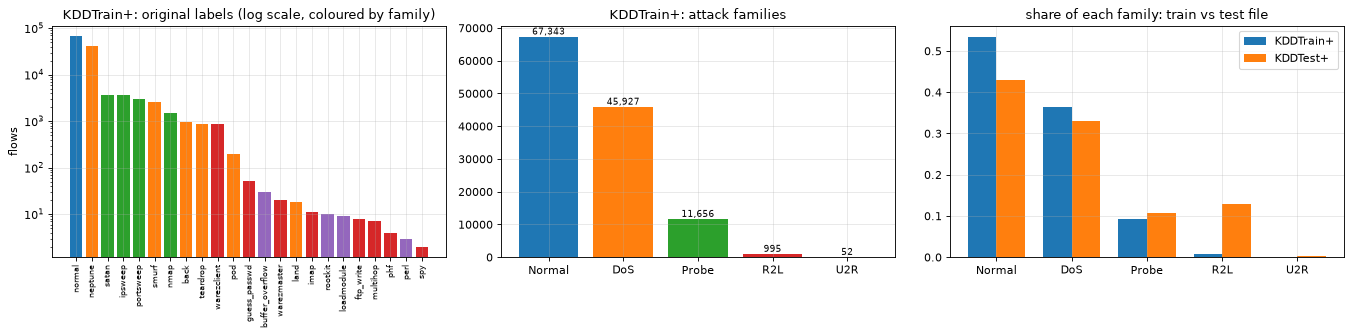

In [8]:
fam_order = list(RAW_TR.family.value_counts().index)
cmap10 = plt.get_cmap("tab10"); fam_col = {f: cmap10(i) for i, f in enumerate(fam_order)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
vc = RAW_TR.attack.value_counts()
ax[0].bar(range(len(vc)), vc.values, color=[fam_col[FAMILY.get(a, "Other")] for a in vc.index]); ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index, rotation=90, fontsize=7)
ax[0].set_yscale("log"); ax[0].set_title("KDDTrain+: original labels (log scale, coloured by family)"); ax[0].set_ylabel("flows")
fc = RAW_TR.family.value_counts(); ax[1].bar(fc.index, fc.values, color=[fam_col[f] for f in fc.index]); ax[1].set_title("KDDTrain+: attack families")
for k, v in enumerate(fc.values): ax[1].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
w = 0.38; fte = RAW_TE.family.value_counts().reindex(fam_order).fillna(0)
ax[2].bar(np.arange(len(fam_order)) - w / 2, fc.reindex(fam_order).values / len(RAW_TR), w, label="KDDTrain+"); ax[2].bar(np.arange(len(fam_order)) + w / 2, fte.values / len(RAW_TE), w, label="KDDTest+")
ax[2].set_xticks(range(len(fam_order))); ax[2].set_xticklabels(fam_order); ax[2].set_title("share of each family: train vs test file"); ax[2].legend()
plt.tight_layout(); plt.show()

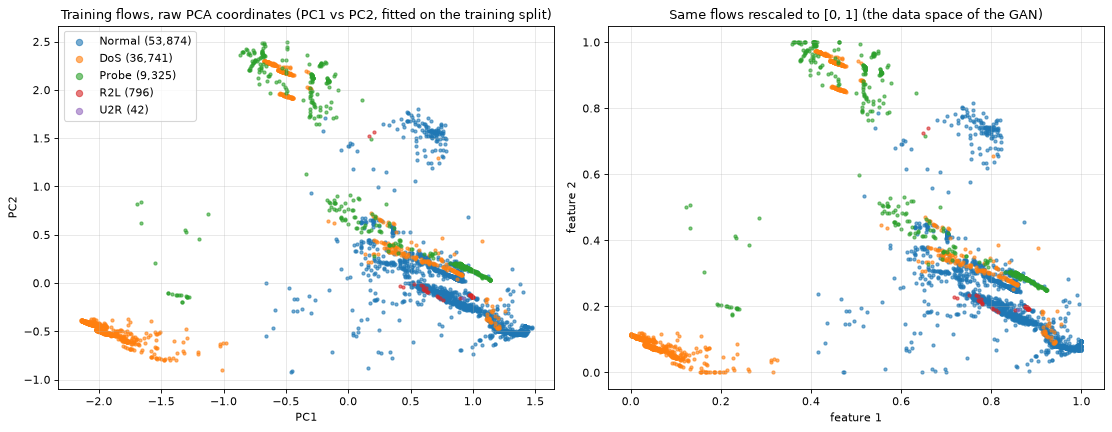

5000 random real training flows shown, coloured by ground-truth family.


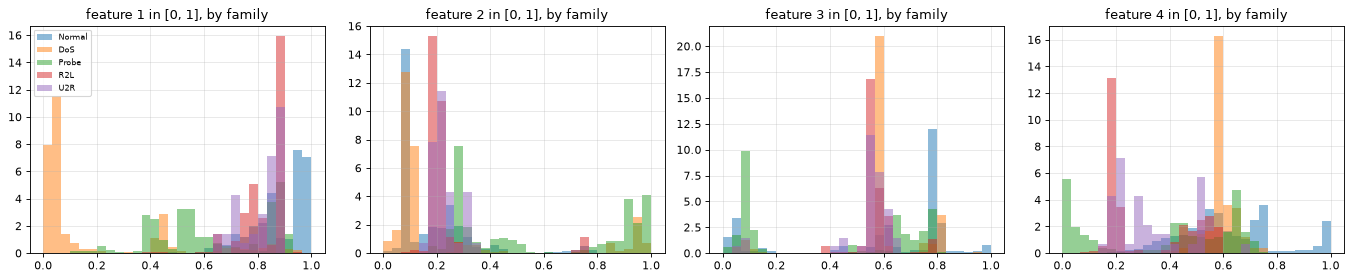

In [9]:
sel = np.random.default_rng(SEED).choice(len(TR_ALL), size=5000, replace=False)
P2 = prep.pca_coords(RAW_TR.loc[TR_ALL[sel], FEATURES]); U2 = U["train"][sel]; f2 = FAMS["train"][sel]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for f in fam_order:
    m = f2 == f
    ax[0].scatter(P2[m, 0], P2[m, 1], s=8, alpha=0.6, color=fam_col[f], label=f"{f} ({(FAMS['train'] == f).sum():,})")
    ax[1].scatter(U2[m, 0], U2[m, 1], s=8, alpha=0.6, color=fam_col[f])
ax[0].set_title("Training flows, raw PCA coordinates (PC1 vs PC2, fitted on the training split)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=2)
ax[1].set_title("Same flows rescaled to [0, 1] (the data space of the GAN)"); ax[1].set_xlabel("feature 1"); ax[1].set_ylabel("feature 2")
plt.tight_layout(); plt.show()
print("5000 random real training flows shown, coloured by ground-truth family.")
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for k in range(N_QUBITS):
    for f in fam_order:
        ax[k].hist(U["train"][FAMS["train"] == f][:, k], bins=30, range=(0, 1), alpha=0.5, color=fam_col[f], density=True, label=f)
    ax[k].set_title(f"feature {k + 1} in [0, 1], by family")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**What the plots show.** The two big families, Normal and DoS, are partly separated in the first two components, Probe sits in between and R2L / U2R (tiny families) overlap with Normal. Only benign flows (the Normal cloud) are shown to the GAN. Four components keep only about 0.7 of the variance (the paper reports 0.71), so some attacks are hard to separate from benign flows in this 4-D space, which caps what any detector built on these inputs can reach.

## Quantum Circuit Architecture

The generator of Section IV-B: for each of the 4 qubits an `RY(z_i)` that loads the latent vector `z`, then the trainable `EfficientSU2` ansatz of depth 4 (`reps=4`: five layers of `RY`, `RZ` rotations and four layers of CNOTs; `circular` entanglement = the CNOT chain plus the wrap-around CNOT between the last and the first qubit), then a measurement of every qubit. The *interpret function* (classical post-processing, CHOICE) turns the 16 outcome probabilities into the 4 marginal probabilities `P(qubit i = 1)`, a synthetic PCA-feature vector in [0, 1]^4.

Three different objects are drawn and used; each one is checked against Qiskit:

1. the **logical circuit** above, executed by the **ideal** simulator (exact state vector in PyTorch, asserted equal to Qiskit's `Statevector`);
2. the **same circuit compiled for `FakeSherbrooke`** (what the IBM device actually executes: only `rz`, `sx`, `x`, `ecr`, with routing on the heavy-hex lattice of the chip), executed by the **noisy** simulator: an exact density-matrix simulation in PyTorch of this gate list, with the noise channels of the backend's noise model after every gate and the read-out error at the end. A cell asserts that its probabilities equal Qiskit Aer's density-matrix simulator with the same noise model, and that read-out errors agree with Aer's shot-based simulation within statistical error;
3. the same compiled circuit with a **finite number of shots** (1024) as the stand-in for a device epoch of the hybrid run (Section 4).

Assumptions where the paper omits circuit details: the `RY` encoding acts on the initial state `|0000>` (no Hadamards); latent angles `z_i ~ U[0, pi]`; initial weights uniform in [-pi, pi]; `circular` entanglement as the text describes (the ablation uses Qiskit's default `reverse_linear`, which needs no wrap-around CNOT and therefore no SWAPs on a line of qubits); the 4 physical qubits are the connected line of 4 qubits of `FakeSherbrooke` with the smallest sum of CNOT and read-out error rates; `transpile(..., optimization_level=1, seed_transpiler=SEED)`.

LOGICAL CIRCUIT: 4 qubits | 4 latent inputs x[i] (not trained) | 40 trainable parameters theta | depth 28 (with measurement) | gate counts {'ry': 24, 'rz': 20, 'cx': 16}


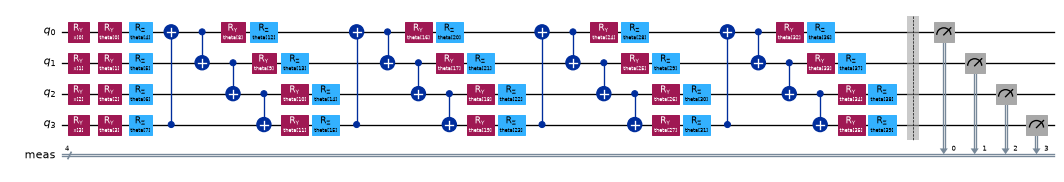

In [10]:
N = N_QUBITS

def logical_circuit(reps=ANSATZ_REPS, ent=ENTANGLEMENT, n=N):
    """RY(z_i) encoding of the latent vector, then the trainable EfficientSU2 ansatz (parameters theta[0..]); no measurement."""
    z = ParameterVector("x", n); qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(z[i], i)
    qc.compose(efficient_su2(n, reps=reps, entanglement=ent, parameter_prefix="theta"), inplace=True)
    return qc

def affine_form(expr, names, n_par):
    """Every rotation angle of the compiled circuit is an affine function of the parameters (checked by sympy): angle = c0 + row . params."""
    if not isinstance(expr, ParameterExpression):
        return float(expr), np.zeros(n_par)
    sy = expr.sympify(); syms = list(sy.free_symbols); row = np.zeros(n_par)
    for s_ in syms:
        assert sympy.diff(sy, s_).is_number, "angle is not affine in the parameters"
        row[names[str(s_)]] = float(sy.diff(s_))
    return float(sy.subs({s_: 0 for s_ in syms})), row

qc_logical = logical_circuit()
qc_meas = qc_logical.copy(); qc_meas.measure_all()
n_theta = sum(1 for p in qc_logical.parameters if p.name.startswith("theta")); n_x = sum(1 for p in qc_logical.parameters if p.name.startswith("x"))
print(f"LOGICAL CIRCUIT: {qc_logical.num_qubits} qubits | {n_x} latent inputs x[i] (not trained) | {n_theta} trainable parameters theta | depth {qc_meas.depth()} (with measurement) | gate counts {dict(qc_logical.count_ops())}")
display(qc_meas.draw("mpl", fold=40, scale=0.6))
plt.close("all")

**Reading the drawing.** Left: one `RY(x[i])` per qubit (the latent vector). Then the `EfficientSU2` ansatz: five columns of `RY(theta)` / `RZ(theta)` rotations, separated by four CNOT blocks; with `circular` entanglement each block contains the wrap-around CNOT between qubit 3 and qubit 0 besides the nearest-neighbour chain. Right: measurement of the four qubits.

In [11]:
backend = FakeSherbrooke()
noise_model = NoiseModel.from_backend(backend)
tgt = backend.target

def best_line(backend, k=4):
    """connected line of k qubits with the smallest sum of ecr and read-out errors (CHOICE)"""
    adj = {}
    for a, b in backend.coupling_map.get_edges():
        adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    def edge_err(a, b):
        for key in [(a, b), (b, a)]:
            if key in tgt["ecr"] and tgt["ecr"][key] is not None:
                return tgt["ecr"][key].error
        return 1.0
    best = None
    def walk(path):
        nonlocal best
        if len(path) == k:
            sc = sum(edge_err(a, b) for a, b in zip(path, path[1:])) + sum(tgt["measure"][(q,)].error for q in path)
            if best is None or sc < best[0]:
                best = (sc, list(path))
            return
        for nb in adj[path[-1]]:
            if nb not in path:
                walk(path + [nb])
    for a in adj:
        walk([a])
    return best[1], best[0]

LAYOUT, LAYOUT_SCORE = best_line(backend, N)
print(f"{backend.name}: {backend.num_qubits} qubits, native gates {sorted(set(backend.operation_names) & {'rz', 'sx', 'x', 'ecr', 'id'})}")
print("chosen physical qubits (a connected line):", LAYOUT, "| summed CNOT + read-out error", round(LAYOUT_SCORE, 4))

fake_sherbrooke: 127 qubits, native gates ['ecr', 'id', 'rz', 'sx', 'x']
chosen physical qubits (a connected line): [122, 123, 124, 125] | summed CNOT + read-out error 0.0438


In [12]:
def pauli_basis(n):
    """Orthonormal Pauli basis of n-qubit density matrices as columns of a (4^n x 4^n) matrix acting on column-stacked vec(rho); index k = sum_q p_q 4^q, p in (I, X, Y, Z)."""
    P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1.0, -1.0])]
    cols = []
    for k in range(4 ** n):
        M = np.ones((1, 1))
        for q in reversed(range(n)):
            M = np.kron(M, P1[(k // 4 ** q) % 4])
        cols.append(M.T.reshape(-1) / math.sqrt(2 ** n))          # column stacking of rho: vec index = row + D * col
    return np.array(cols).T

def draw_params(n_theta, seed):
    return ((torch.rand(n_theta, generator=torch.Generator().manual_seed(1000 + seed)) * 2 - 1) * math.pi)      # CHOICE: initial weights uniform in [-pi, pi]

class IdealGenerator(nn.Module):
    """Exact differentiable state-vector simulation of the logical circuit (gate list = the Qiskit circuit written as ry / rz / cx)."""
    kind = "ideal"
    def __init__(self, reps=ANSATZ_REPS, ent=ENTANGLEMENT, n=N, init_seed=0):
        super().__init__()
        self.n = n; self.qc = logical_circuit(reps, ent, n)
        self.xp = [p for p in self.qc.parameters if p.name.startswith("x")]; self.tp = [p for p in self.qc.parameters if p.name.startswith("theta")]
        names = {p.name: k for k, p in enumerate(self.xp + self.tp)}
        dec = transpile(self.qc, basis_gates=["ry", "rz", "cx"], optimization_level=0)
        self.ops = []
        for inst in dec.data:
            op = inst.operation; qs = tuple(dec.find_bit(q).index for q in inst.qubits)
            self.ops.append((op.name, qs, affine_form(op.params[0], names, len(names)) if op.params else None))
        self.A = torch.tensor(np.array([o[2][1] for o in self.ops if o[2] is not None])); self.c = torch.tensor(np.array([o[2][0] for o in self.ops if o[2] is not None]))
        self.theta = nn.Parameter(draw_params(len(self.tp), init_seed))
        self.register_buffer("marg", torch.tensor([[(s >> i) & 1 for i in range(n)] for s in range(2 ** n)], dtype=torch.float64))
        self.perm = {}
    def probs(self, x):
        B = x.shape[0]
        ang = torch.cat([x, self.theta[None].expand(B, -1)], 1) @ self.A.T + self.c          # (B, n_rot): all rotation angles at once
        st = torch.zeros((B,) + (2,) * self.n, dtype=torch.complex128); st[(slice(None),) + (0,) * self.n] = 1
        k = 0
        for name, qs, a in self.ops:
            if name == "cx":
                if qs not in self.perm:
                    self.perm[qs] = torch.tensor([i ^ (1 << qs[1]) if (i >> qs[0]) & 1 else i for i in range(2 ** self.n)])
                st = st.reshape(B, -1)[:, self.perm[qs]].reshape(st.shape); continue
            th = ang[:, k]; k += 1
            ax = self.n - qs[0]                                                              # axis of qubit q in (B, q_{n-1}, ..., q_0)
            s = torch.movedim(st, ax, -1); shp = s.shape; s = s.reshape(B, -1, 2)
            if name == "ry":
                c_, s_ = torch.cos(th / 2), torch.sin(th / 2)
                U = torch.stack([torch.stack([c_, -s_], -1), torch.stack([s_, c_], -1)], -2).to(torch.complex128)
            else:
                e = torch.exp(-0.5j * th); z0 = torch.zeros_like(e)
                U = torch.stack([torch.stack([e, z0], -1), torch.stack([z0, e.conj()], -1)], -2)
            st = torch.movedim(torch.einsum("bnj,bij->bni", s, U).reshape(shp), -1, ax)
        return st.reshape(B, -1).abs() ** 2
    def forward(self, x, device=False):                    # interpret function: marginal P(qubit i = 1)
        return self.probs(x) @ self.marg

class NoisyGenerator(nn.Module):
    """Exact density-matrix simulation of the circuit transpiled for a fake IBM backend, with the noise channels of the backend's noise model.
    The state is the real vector of the Pauli coefficients of rho (4^n numbers), so every 'gate + noise' block is a real matrix (Pauli transfer matrix);
    an rz layer rotates the (X, Y) coefficients of its qubit. Fixed gates between two rz layers are multiplied into one matrix."""
    kind = "noisy"
    def __init__(self, backend, noise_model, layout, reps=ANSATZ_REPS, ent=ENTANGLEMENT, n=N, init_seed=0, noise=True, shots=SHOTS, seed_transpiler=SEED, dtype=torch.float64):
        super().__init__()
        self.n = n; self.shots = shots; self.dt = dtype; self.qc = logical_circuit(reps, ent, n)
        self.xp = [p for p in self.qc.parameters if p.name.startswith("x")]; self.tp = [p for p in self.qc.parameters if p.name.startswith("theta")]
        names = {p.name: k for k, p in enumerate(self.xp + self.tp)}; npar = len(names)
        qm = self.qc.copy(); qm.measure_all()
        self.transpiled = transpile(qm, backend, initial_layout=list(layout), optimization_level=1, seed_transpiler=seed_transpiler)
        t = self.transpiled; meas = {}
        for inst in t.data:
            if inst.operation.name == "measure":
                meas[t.find_bit(inst.clbits[0]).index] = t.find_bit(inst.qubits[0]).index        # logical bit i -> physical qubit
        body = t.remove_final_measurements(inplace=False); self.body = body
        act = sorted({body.find_bit(q).index for inst in body.data for q in inst.qubits} | set(meas.values()))
        loc = {p: k for k, p in enumerate(act)}; self.nA = nA = len(act); D = 2 ** nA; self.D = D; self.act = act; K = 4 ** nA; self.K = K
        self.meas_local = [loc[meas[i]] for i in range(n)]
        T = pauli_basis(nA); eye = SuperOp(np.eye(D * D)); cache = {}
        def embedded(name, phys, lq, op):                  # gate followed by its noise channel, as an nA-qubit superoperator
            key = (name, phys)
            if key not in cache:
                S = eye.compose(SuperOp(Operator(op)), qargs=lq)
                if noise and name in noise_model._local_quantum_errors and phys in noise_model._local_quantum_errors[name]:
                    S = S.compose(noise_model._local_quantum_errors[name][phys].to_quantumchannel(), qargs=lq)
                M = T.conj().T @ S.data @ T                 # Pauli transfer matrix: real because the channel maps Hermitian to Hermitian operators
                assert np.abs(M.imag).max() < 1e-9
                cache[key] = M.real
            return cache[key]
        def to_ptm(M):
            return torch.tensor(M, dtype=dtype)
        rz_rows, rz_c, rz_q, plan, pending = [], [], [], [], None
        for layer in circuit_to_dag(body).layers():
            rzs, fixed = [], []
            for nd in layer["graph"].op_nodes():
                phys = tuple(body.find_bit(q).index for q in nd.qargs); lq = [loc[p] for p in phys]
                if nd.op.name == "rz":                    # virtual gate, no noise on IBM devices
                    c0, row = affine_form(nd.op.params[0], names, npar)
                    rz_rows.append(row); rz_c.append(c0); rz_q.append(lq[0]); rzs.append(len(rz_c) - 1)
                elif nd.op.name != "barrier":
                    assert nd.op.name in ("sx", "x", "ecr", "id"), nd.op.name
                    fixed.append(embedded(nd.op.name, phys, lq, nd.op))
            if rzs:
                if pending is not None:
                    plan.append(("S", to_ptm(pending))); pending = None
                plan.append(("rz", rzs))
            for S in fixed:
                pending = S if pending is None else S @ pending
        if pending is not None:
            plan.append(("S", to_ptm(pending)))
        self.plan = plan; self.A = torch.tensor(np.array(rz_rows), dtype=dtype); self.c = torch.tensor(np.array(rz_c), dtype=dtype); self.rz_q = torch.tensor(rz_q); self.rzl = list(rz_q)
        digit = lambda k, q: (k // 4 ** q) % 4
        self.mXY = torch.tensor([[1.0 if digit(k, q) in (1, 2) else 0.0 for k in range(K)] for q in range(nA)], dtype=dtype)
        self.sgn = torch.tensor([[-1.0 if digit(k, q) == 1 else (1.0 if digit(k, q) == 2 else 0.0) for k in range(K)] for q in range(nA)], dtype=dtype)
        swap = lambda k, q: k + (3 - 2 * digit(k, q)) * 4 ** q if digit(k, q) in (1, 2) else k          # exchange X <-> Y in digit q
        self.perm = [torch.tensor([swap(k, q) for k in range(K)]) for q in range(nA)]
        v0 = np.zeros(D * D, dtype=complex); v0[0] = 1                                                    # |0..0><0..0|
        self.c0 = torch.tensor((T.conj().T @ v0).real, dtype=dtype)
        self.Dg = torch.tensor(np.array([[(T[i * D + i, k]).real for i in range(D)] for k in range(K)]), dtype=dtype)    # Pauli coefficients -> probability of basis state i
        R = np.ones((1, 1))
        for i in reversed(range(n)):                       # logical bit n-1 is the most significant bit of an outcome
            C = np.eye(2)
            if noise and (meas[i],) in noise_model._local_readout_errors:
                C = np.array(noise_model._local_readout_errors[(meas[i],)].probabilities)      # rows: true 0/1, columns: read 0/1
            R = np.kron(R, C)
        self.R = torch.tensor(R, dtype=dtype)              # R[true outcome, read outcome]
        M = np.zeros((D, 2 ** n))
        for b in range(D):
            M[b, sum(((b >> self.meas_local[i]) & 1) << i for i in range(n))] = 1
        self.M = torch.tensor(M, dtype=dtype)
        self.theta = nn.Parameter(draw_params(len(self.tp), init_seed).to(dtype))
        self.register_buffer("marg", torch.tensor([[(s >> i) & 1 for i in range(n)] for s in range(2 ** n)], dtype=dtype))
        self.shot_gen = torch.Generator().manual_seed(3000 + init_seed)
    def pre_readout(self, x):
        B = x.shape[0]
        ang = torch.cat([x.to(self.dt), self.theta[None].expand(B, -1)], 1) @ self.A.T + self.c          # (B, n_rz): every rz angle of the compiled circuit
        F1 = (1 + (torch.cos(ang) - 1)[:, :, None] * self.mXY[self.rz_q][None]).unbind(1)      # unbind: one backward pass instead of one zero-filled copy per gate
        F2 = (torch.sin(ang)[:, :, None] * self.sgn[self.rz_q][None]).unbind(1)
        c = self.c0[None].expand(B, -1)
        for kind, item in self.plan:
            if kind == "S":
                c = c @ item.T
            else:
                for j in item:                              # rz layer: rotate the (X, Y) coefficients of the qubit
                    c = c * F1[j] + c[:, self.perm[self.rzl[j]]] * F2[j]
        return (c @ self.Dg) @ self.M                       # (B, 2^n): outcome probabilities of the measured qubits, before read-out error
    def joint(self, x, readout=True):
        P = self.pre_readout(x)
        return P @ self.R if readout else P
    def forward(self, x, device=False):
        P = self.joint(x); g = P @ self.marg
        if device:                                          # finite-shot stand-in for a device epoch: forward = shot estimate, gradient = exact one (straight-through)
            idx = torch.multinomial(P.detach().clamp_min(0), self.shots, replacement=True, generator=self.shot_gen)
            cnt = torch.nn.functional.one_hot(idx, P.shape[1]).sum(1).to(P.dtype)
            g = g + (cnt / self.shots @ self.marg - g).detach()
        return g

t0 = time.time()
ideal = IdealGenerator(init_seed=1)
noisy64 = NoisyGenerator(backend, noise_model, LAYOUT, init_seed=1)
noisy64_clean = NoisyGenerator(backend, noise_model, LAYOUT, init_seed=1, noise=False)
print(f"simulators built in {time.time() - t0:.1f} s | compiled circuit acts on physical qubits {noisy64.act} | {len(noisy64.plan)} blocks")

simulators built in 5.9 s | compiled circuit acts on physical qubits [122, 123, 124, 125] | 249 blocks


COMPILED FOR fake_sherbrooke: 4 physical qubits [122, 123, 124, 125] | depth 184 | gate counts {'rz': 240, 'sx': 144, 'ecr': 64, 'x': 12} | two-qubit gates (ecr): 64 | trainable parameters 40 | latent inputs 4


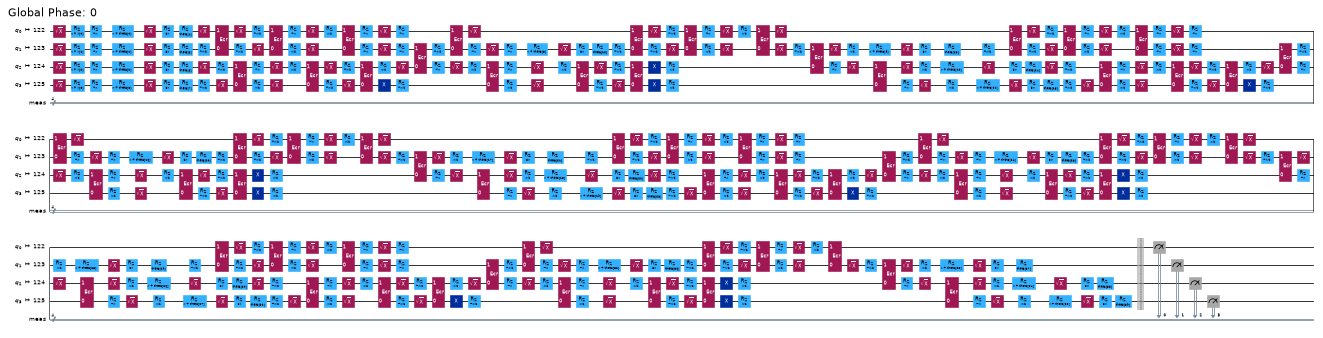

In [13]:
tc = noisy64.transpiled
ops = dict(tc.count_ops()); ops.pop("measure", None); ops.pop("barrier", None)
print(f"COMPILED FOR {backend.name}: {len(noisy64.act)} physical qubits {noisy64.act} | depth {tc.depth()} | gate counts {ops} | two-qubit gates (ecr): {ops.get('ecr', 0)} | trainable parameters {len(noisy64.tp)} | latent inputs {len(noisy64.xp)}")
display(tc.draw("mpl", fold=70, scale=0.35, idle_wires=False))
plt.close("all")

**Reading the second drawing.** Only the four physical qubits that carry the circuit are shown. Every rotation of the logical circuit became a few `rz` (virtual, error-free on IBM hardware) and `sx` (a noisy pulse) gates, and every CNOT an `ecr` (echoed cross-resonance) gate with single-qubit corrections. Because the four qubits sit on a line and `circular` entanglement needs a CNOT between the two ends, the transpiler inserted SWAPs (three more two-qubit gates each), which is why this circuit has several times more two-qubit gates than the logical one. The ablation with `reverse_linear` entanglement removes them. This is where the hardware noise enters.

**Equivalence checks.** The next cell asserts: (1) the ideal PyTorch simulator equals Qiskit's `Statevector` of the logical circuit; (2) the noise-free version of the compiled circuit equals the ideal simulator (the compilation and routing preserve the function, including the read-out qubit mapping); (3) the noisy PyTorch simulator equals Qiskit Aer's density-matrix simulation with the noise model of `FakeSherbrooke` (probabilities before read-out) to machine precision; (4) after the read-out error, Aer's shot-based counts agree with the simulator within five standard errors.

In [14]:
zc = torch.rand(6, N, generator=torch.Generator().manual_seed(7)) * math.pi
for m_ in (ideal, noisy64, noisy64_clean):
    m_.theta.data = draw_params(len(ideal.tp), 1)

# (1) ideal simulator == Qiskit Statevector
worst1 = 0.0
for r in range(6):
    bound = ideal.qc.assign_parameters({**{p: float(zc[r, k]) for k, p in enumerate(ideal.xp)}, **{p: float(ideal.theta[k]) for k, p in enumerate(ideal.tp)}})
    worst1 = max(worst1, np.abs(Statevector(bound).probabilities() - ideal.probs(zc)[r].detach().numpy()).max())
# (2) compiled circuit without noise == ideal
worst2 = (noisy64_clean.joint(zc).detach() - ideal.probs(zc).detach()).abs().max().item()
# (3) noisy simulator == Aer density matrix with the backend noise model (before read-out error)
sim_dm = AerSimulator(method="density_matrix", noise_model=noise_model)
tq = noisy64.transpiled.remove_final_measurements(inplace=False)
worst3 = 0.0
for r in range(4):
    bnd = tq.assign_parameters({**{p: float(zc[r, k]) for k, p in enumerate(noisy64.xp)}, **{p: float(noisy64.theta[k]) for k, p in enumerate(noisy64.tp)}})
    bnd.save_probabilities(qubits=LAYOUT, label="p")
    pa = np.array(sim_dm.run(bnd, shots=1).result().data()["p"])           # little-endian over LAYOUT = logical bit order
    worst3 = max(worst3, np.abs(pa - noisy64.joint(zc, readout=False)[r].detach().numpy()).max())
# (4) read-out error: Aer shot-based counts of the measured transpiled circuit vs the simulator
NCHK = 40000
sim_sh = AerSimulator(noise_model=noise_model, seed_simulator=SEED)
z4 = 0
for r in range(2):
    bnd = noisy64.transpiled.assign_parameters({**{p: float(zc[r, k]) for k, p in enumerate(noisy64.xp)}, **{p: float(noisy64.theta[k]) for k, p in enumerate(noisy64.tp)}})
    counts = sim_sh.run(bnd, shots=NCHK, seed_simulator=SEED).result().get_counts()
    emp = np.zeros(2 ** N)
    for key, v in counts.items():
        emp[int(key.replace(" ", ""), 2)] += v / NCHK
    ex = noisy64.joint(zc, readout=True)[r].detach().numpy()
    z4 = max(z4, np.max(np.abs(emp - ex) / np.sqrt(np.maximum(ex * (1 - ex), 1e-4) / NCHK)))
print(f"(1) ideal PyTorch vs Qiskit Statevector          : max |dP| = {worst1:.1e}")
print(f"(2) compiled circuit, no noise, vs ideal          : max |dP| = {worst2:.1e}")
print(f"(3) noisy PyTorch vs Aer density matrix + noise   : max |dP| = {worst3:.1e}")
print(f"(4) with read-out error vs Aer shots ({NCHK})      : max deviation = {z4:.1f} standard errors")
assert worst1 < 1e-9 and worst2 < 1e-9 and worst3 < 1e-9 and z4 < 5.5
m_ = noisy64.joint(zc)[0].detach().numpy(); p_ = ideal.probs(zc)[0].detach().numpy()
print("\nexample outcome distribution (first latent vector): total-variation distance ideal vs noisy FakeSherbrooke =", round(0.5 * np.abs(m_ - p_).sum(), 4))

(1) ideal PyTorch vs Qiskit Statevector          : max |dP| = 2.8e-16
(2) compiled circuit, no noise, vs ideal          : max |dP| = 3.3e-15
(3) noisy PyTorch vs Aer density matrix + noise   : max |dP| = 3.3e-16
(4) with read-out error vs Aer shots (40000)      : max deviation = 2.6 standard errors



example outcome distribution (first latent vector): total-variation distance ideal vs noisy FakeSherbrooke = 0.1202


**What the noise does to the generator.** The total-variation distance above is how far the noisy device's output distribution is from the ideal one for a random generator; with the many two-qubit gates of the compiled circuit it is large, which is why the noisy and ideal GANs can behave differently. (The paper does not discuss this.)

The float32 simulator that the training uses is cross-checked against the float64 one in the next cell, and the ablation circuit (`reverse_linear`) is compiled for comparison.

In [15]:
DT = torch.float32 if GEN_DTYPE == "float32" else torch.float64
t0 = time.time()
def make_noisy(init_seed, ent=ENTANGLEMENT):
    return NoisyGenerator(backend, noise_model, LAYOUT, ent=ent, init_seed=init_seed, dtype=DT)
g32 = make_noisy(1); g32.theta.data = draw_params(len(g32.tp), 1).to(DT)
d32 = (g32.joint(zc).detach().double() - noisy64.joint(zc).detach()).abs().max().item()
print(f"{GEN_DTYPE} simulator vs float64 simulator: max |dP| = {d32:.1e}  (built in {time.time() - t0:.1f} s)")
assert d32 < 1e-4
rows = []
for ent in [ENTANGLEMENT, ABLATE_ENTANGLEMENT]:
    qm_ = logical_circuit(ent=ent); qm_.measure_all()
    tc_ = transpile(qm_, backend, initial_layout=LAYOUT, optimization_level=1, seed_transpiler=SEED)
    o = dict(tc_.count_ops())
    rows.append(dict(entanglement=ent, qubits=4, trainable_params=n_theta, depth_logical=qm_.depth(), depth_compiled=tc_.depth(), ecr=o.get("ecr", 0), sx=o.get("sx", 0), rz=o.get("rz", 0), x=o.get("x", 0)))
display(pd.DataFrame(rows))

float32 simulator vs float64 simulator: max |dP| = 9.4e-08  (built in 6.7 s)


,entanglement,qubits,trainable_params,depth_logical,depth_compiled,ecr,sx,rz,x
0,circular,4,40,28,184,64,144,240,12
1,reverse_linear,4,40,21,64,12,56,124,8


## 3. Discriminator, GAN losses, FID and the training loop

* **Discriminator** `D`: `4 -> 32 -> 16 -> 1`, ReLU between layers, sigmoid output (CHOICE of the widths; the paper says "two hidden layers with ReLU, sigmoid output").
* **Losses**: the usual GAN losses with binary cross-entropy, `L_D = -E[log D(x)] - E[log(1 - D(G(z)))]`, `L_G = -E[log D(G(z))]`; Adam for both networks. One *epoch* draws `SAMPLES_PER_EPOCH` benign flows from the pool and makes `SAMPLES_PER_EPOCH / BATCH` discriminator steps, each followed by a generator step on the same batch of latent vectors.
* **Frechet distance (FID).** The paper calls it Frechet *Inception* Distance; there is no Inception network for 4-D tabular data, so (CHOICE) the Frechet distance between the Gaussians fitted to 200 generated samples (fixed latent vectors, so the curve is not noisy) and to 1000 real held-out benign samples in the 4-D [0, 1] feature space: `|mu_1 - mu_2|^2 + Tr(S_1 + S_2 - 2 (S_1 S_2)^(1/2))`. Lower is better.
* **Accuracies** (CHOICE, the paper does not define them): discriminator accuracy = mean of the share of real samples classified real and of fake samples classified fake (threshold 0.5), averaged over the epoch's steps; generator accuracy = share of generated samples that the discriminator classifies as real.
* **Hybrid epochs.** In a hybrid run every tenth epoch (epochs 10, 20, ...) is a *device* epoch: the generator is evaluated with `device=True`, i.e. with 1024-shot sampling of the noisy circuit (straight-through gradient from the exact noisy simulation, which is what a parameter-shift/gradient estimate from a shot-based device would approximate). With `USE_IBM_IN_TRAINING = True` and an `IBM_TOKEN`, these epochs sample the real IBM device instead.

In [16]:
def sample_noise(B, gen):
    return torch.rand(B, N, generator=gen) * math.pi                  # CHOICE: latent z ~ U[0, pi]^4

def make_disc(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(N, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())

class ClassicalGenerator(nn.Module):
    """Control, not in the paper: classical generator noise (4) -> 16 -> 16 -> 4 (sigmoid), 420 parameters, same latent distribution."""
    kind = "classical"
    def __init__(self, init_seed=0):
        super().__init__()
        torch.manual_seed(1000 + init_seed)
        self.net = nn.Sequential(nn.Linear(N, 16), nn.LeakyReLU(0.2), nn.Linear(16, 16), nn.LeakyReLU(0.2), nn.Linear(16, N), nn.Sigmoid())
    def forward(self, x, device=False):
        return self.net(x / math.pi)

class UniformGenerator(nn.Module):
    """Control, not in the paper: no generator; the 'fakes' are uniform random numbers in [0, 1]^4, so D only learns benign flows against uniform noise."""
    kind = "uniform"
    def __init__(self, init_seed=0):
        super().__init__()
        self.dummy = nn.Parameter(torch.zeros(1)); self.g = torch.Generator().manual_seed(2000 + init_seed)
    def forward(self, x, device=False):
        return torch.rand(x.shape[0], N, generator=self.g) + 0 * self.dummy

REAL_FID = U["benval"][:N_FID_REAL]
Z_EVAL = sample_noise(N_FID, torch.Generator().manual_seed(SEED + 7))        # fixed latent vectors for the FID
Z_VIS = sample_noise(1000, torch.Generator().manual_seed(SEED + 8))          # fixed latent vectors for the scatter plots

def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    cs = sqrtm(s1 @ s2).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * cs))

def generated(gen, Z):
    with torch.no_grad():
        return gen(Z).double().numpy()

def fid_of(gen):
    return frechet(generated(gen, Z_EVAL), REAL_FID)

print("FID between two disjoint halves of the real benign validation flows (the floor for this sample size):", round(frechet(U["benval"][:200], U["benval"][200:1000]), 5))
print("FID of uniform noise in [0,1]^4 versus real benign flows (a bad generator):", round(frechet(np.random.default_rng(SEED).random((200, N)), REAL_FID), 4))

FID between two disjoint halves of the real benign validation flows (the floor for this sample size): 0.00328
FID of uniform noise in [0,1]^4 versus real benign flows (a bad generator): 0.3851


In [17]:
def ibm_marginals(theta, Z, backend_name=IBM_BACKEND, shots=SHOTS):
    """Sample the generator circuit on a real IBM device (needs IBM_TOKEN; NOT executed in the published run). Returns the marginals P(qubit i = 1)."""
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    be = service.backend(backend_name)
    qm_ = logical_circuit(); qm_.measure_all()
    isa = transpile(qm_, be, initial_layout=list(LAYOUT), optimization_level=1, seed_transpiler=SEED)
    names = {p.name: k for k, p in enumerate(isa.parameters)}
    vals = np.zeros((len(Z), len(isa.parameters)))
    for p in isa.parameters:
        vals[:, names[p.name]] = Z[:, int(p.name[2:-1])] if p.name.startswith("x") else float(theta[int(p.name[6:-1])])
    res = SamplerV2(mode=be).run([(isa, vals)], shots=shots).result()[0]
    out = np.zeros((len(Z), N))
    for r in range(len(Z)):
        for key, v in res.data.meas.get_counts(r).items():
            bits = key[::-1]
            out[r] += np.array([int(bits[i]) for i in range(N)]) * v / shots
    return out

bce = nn.BCELoss()

def train_gan(gen, label, epochs, seed, hybrid=False, lr_g=None, lr_d=None, samples=None, verbose=True):
    lr_g = LR_G if lr_g is None else lr_g; lr_d = LR_D if lr_d is None else lr_d; samples = SAMPLES_PER_EPOCH if samples is None else samples
    D = make_disc(seed); oG = torch.optim.Adam(gen.parameters(), lr=lr_g); oD = torch.optim.Adam(D.parameters(), lr=lr_d)
    rs = np.random.default_rng(seed); zg = torch.Generator().manual_seed(seed)
    X = torch.as_tensor(U["pool"]); rows = []; t_run = time.process_time()
    ones, zeros = torch.ones(BATCH), torch.zeros(BATCH)
    for ep in range(epochs):
        dev = bool(hybrid and ep % HYBRID_PERIOD == HYBRID_PERIOD - 1)
        Xr = X[torch.as_tensor(rs.choice(len(X), samples, replace=False))]; steps = samples // BATCH
        lg = ld = ad = ag = 0.0; t_ep = time.process_time()
        for s in range(steps):
            real = Xr[s * BATCH:(s + 1) * BATCH]; z = sample_noise(BATCH, zg)
            fake = gen(z, device=dev).double()
            if dev and USE_IBM_IN_TRAINING and IBM_TOKEN:                       # hardware-in-the-loop: forward from the real device, gradient from the noisy simulator
                fake = fake + (torch.as_tensor(ibm_marginals(gen.theta.detach().numpy(), z.numpy())) - fake).detach()
            oD.zero_grad()
            pr, pf = D(real).squeeze(1), D(fake.detach()).squeeze(1)
            l_d = bce(pr, ones) + bce(pf, zeros); l_d.backward(); oD.step()
            oG.zero_grad(); l_g = bce(D(fake).squeeze(1), ones); l_g.backward(); oG.step()
            lg += l_g.item(); ld += l_d.item()
            ad += 0.5 * ((pr > 0.5).double().mean().item() + (pf <= 0.5).double().mean().item()); ag += (pf > 0.5).double().mean().item()
        rows.append(dict(epoch=ep + 1, device_epoch=dev, loss_G=lg / steps, loss_D=ld / steps, acc_D=ad / steps, acc_G=ag / steps, fid=fid_of(gen), sec=time.process_time() - t_ep))
        if verbose and (ep == 0 or (ep + 1) % max(1, epochs // 6) == 0 or ep + 1 == epochs):
            r = rows[-1]; print(f"  [{label} seed {seed}] epoch {ep + 1:3d}/{epochs}  FID {r['fid']:.4f}  D acc {r['acc_D']:.3f}  G acc {r['acc_G']:.3f}  loss G {r['loss_G']:.3f} D {r['loss_D']:.3f}  ({time.process_time() - t_run:.0f} s so far)")
    return dict(hist=pd.DataFrame(rows), gen=gen, D=D, secs=time.process_time() - t_run, label=label, seed=seed)

RUNS = {}

### 3.1 Choosing the learning rates (the paper does not give them)

A small grid on the **ideal** simulator (cheap), judged by the final FID only (no use of the paper's numbers and no test data). The values in the configuration cell are the ones used for all runs below; the grid shows how sensitive the result is.

In [18]:
t0 = time.time(); grid = []
for lg_, ld_ in itertools.product([0.01, 0.03], [0.001, 0.002, 0.005]):
    r = train_gan(IdealGenerator(init_seed=SEED), "grid", 25, SEED, lr_g=lg_, lr_d=ld_, samples=100, verbose=False)["hist"]
    grid.append(dict(LR_G=lg_, LR_D=ld_, FID_last3=r.fid.tail(3).mean(), acc_D=r.acc_D.tail(3).mean(), acc_G=r.acc_G.tail(3).mean()))
grid = pd.DataFrame(grid).sort_values("FID_last3")
display(grid.round(4)); print(f"grid done in {time.time() - t0:.0f} s (25 epochs of 100 samples, ideal simulator, seed {SEED}); used in this notebook: LR_G={LR_G}, LR_D={LR_D}")

,LR_G,LR_D,FID_last3,acc_D,acc_G
4,0.03,0.002,0.0568,0.6333,0.4400
1,0.01,0.002,0.0653,0.7200,0.2867
0,0.01,0.001,0.0805,0.7533,0.1500
2,0.01,0.005,0.0946,0.7850,0.2267
3,0.03,0.001,0.1082,0.5117,0.6733
5,0.03,0.005,0.2005,0.7733,0.1967


grid done in 214 s (25 epochs of 100 samples, ideal simulator, seed 42); used in this notebook: LR_G=0.03, LR_D=0.002


## 4. The runs

Four GANs share the same discriminator, benign pool, optimiser and seed; they differ in the generator.

1. **Ideal simulator** (exact state vector): the "no hardware" reference. Not in the paper (the authors only mention an earlier ideal-versus-noisy comparison).
2. **Noisy simulator** `FakeSherbrooke`: the paper's 220-epoch run (fewer epochs in `FAST_MODE`).
3. **Hybrid**: the paper's 90-epoch run with nine noisy-emulator epochs and one device epoch in turn. **The device epoch is a finite-shot stand-in unless `IBM_TOKEN` is set**, so this run is not independent evidence about the real device.
4. **Classical generator** (control, not in the paper; once with the same optimiser settings as the quantum generator and once with a lower generator learning rate, 0.003, because a classical network does not need the quantum generator's large rate) and a **uniform-noise** "generator" (control): what does the quantum circuit add?

In [19]:
for sd in SEEDS_CHEAP:
    RUNS[("Ideal simulator", sd)] = train_gan(IdealGenerator(init_seed=sd), "ideal", EPOCHS_NOISY, sd)
print({k: round(v["secs"]) for k, v in RUNS.items()}, "s")

  [ideal seed 42] epoch   1/220  FID 0.1662  D acc 0.522  G acc 0.930  loss G 0.681 D 1.373  (1 s so far)


  [ideal seed 42] epoch  36/220  FID 0.0458  D acc 0.713  G acc 0.297  loss G 1.049 D 1.127  (42 s so far)


  [ideal seed 42] epoch  72/220  FID 0.0490  D acc 0.762  G acc 0.260  loss G 0.971 D 1.059  (82 s so far)


  [ideal seed 42] epoch 108/220  FID 0.0587  D acc 0.775  G acc 0.217  loss G 1.391 D 0.967  (121 s so far)


  [ideal seed 42] epoch 144/220  FID 0.0761  D acc 0.865  G acc 0.133  loss G 1.464 D 0.801  (157 s so far)


...

  [ideal seed 44] epoch 108/220  FID 0.0762  D acc 0.722  G acc 0.220  loss G 1.045 D 1.151  (122 s so far)


  [ideal seed 44] epoch 144/220  FID 0.0599  D acc 0.800  G acc 0.143  loss G 1.139 D 0.952  (161 s so far)


  [ideal seed 44] epoch 180/220  FID 0.1535  D acc 0.803  G acc 0.070  loss G 1.640 D 0.842  (198 s so far)


  [ideal seed 44] epoch 216/220  FID 0.0860  D acc 0.817  G acc 0.103  loss G 1.403 D 0.847  (236 s so far)


  [ideal seed 44] epoch 220/220  FID 0.0788  D acc 0.808  G acc 0.123  loss G 1.258 D 0.908  (240 s so far)
{('Ideal simulator', 42): 248, ('Ideal simulator', 43): 236, ('Ideal simulator', 44): 240} s


In [20]:
for sd in SEEDS_NOISY:
    RUNS[("Noisy simulator FakeSherbrooke", sd)] = train_gan(make_noisy(sd), "noisy", EPOCHS_NOISY, sd)
print({k: round(v["secs"]) for k, v in RUNS.items()}, "s")

  [noisy seed 42] epoch   1/220  FID 0.2243  D acc 0.540  G acc 0.893  loss G 0.684 D 1.369  (3 s so far)


  [noisy seed 42] epoch  36/220  FID 0.1501  D acc 0.823  G acc 0.177  loss G 1.895 D 0.728  (109 s so far)


  [noisy seed 42] epoch  72/220  FID 0.0723  D acc 0.857  G acc 0.110  loss G 1.848 D 0.668  (220 s so far)


  [noisy seed 42] epoch 108/220  FID 0.2091  D acc 0.830  G acc 0.143  loss G 1.913 D 0.738  (324 s so far)


  [noisy seed 42] epoch 144/220  FID 0.1108  D acc 0.885  G acc 0.043  loss G 2.113 D 0.511  (438 s so far)


  [noisy seed 42] epoch 180/220  FID 0.1564  D acc 0.878  G acc 0.033  loss G 1.916 D 0.579  (545 s so far)


  [noisy seed 42] epoch 216/220  FID 0.2185  D acc 0.813  G acc 0.157  loss G 1.886 D 0.697  (666 s so far)


  [noisy seed 42] epoch 220/220  FID 0.0901  D acc 0.853  G acc 0.097  loss G 2.121 D 0.691  (680 s so far)
{('Ideal simulator', 42): 248, ('Ideal simulator', 43): 236, ('Ideal simulator', 44): 240, ('Noisy simulator FakeSherbrooke', 42): 680} s


In [21]:
for sd in SEEDS_NOISY:
    RUNS[("Hybrid (noisy + device epochs)", sd)] = train_gan(make_noisy(sd), "hybrid", EPOCHS_HYBRID, sd, hybrid=True)
print({k: round(v["secs"]) for k, v in RUNS.items()}, "s")

  [hybrid seed 42] epoch   1/90  FID 0.2243  D acc 0.540  G acc 0.893  loss G 0.684 D 1.369  (4 s so far)


  [hybrid seed 42] epoch  15/90  FID 0.1104  D acc 0.797  G acc 0.170  loss G 1.270 D 0.910  (53 s so far)


  [hybrid seed 42] epoch  30/90  FID 0.1027  D acc 0.803  G acc 0.157  loss G 1.711 D 0.829  (108 s so far)


  [hybrid seed 42] epoch  45/90  FID 0.0741  D acc 0.857  G acc 0.103  loss G 1.981 D 0.685  (153 s so far)


  [hybrid seed 42] epoch  60/90  FID 0.1177  D acc 0.857  G acc 0.087  loss G 1.860 D 0.720  (199 s so far)


  [hybrid seed 42] epoch  75/90  FID 0.0930  D acc 0.862  G acc 0.067  loss G 1.944 D 0.690  (244 s so far)


  [hybrid seed 42] epoch  90/90  FID 0.0858  D acc 0.857  G acc 0.110  loss G 1.961 D 0.688  (289 s so far)
{('Ideal simulator', 42): 248, ('Ideal simulator', 43): 236, ('Ideal simulator', 44): 240, ('Noisy simulator FakeSherbrooke', 42): 680, ('Hybrid (noisy + device epochs)', 42): 289} s


In [22]:
for sd in SEEDS_CHEAP:
    RUNS[("Classical generator (control)", sd)] = train_gan(ClassicalGenerator(init_seed=sd), "classical", EPOCHS_NOISY, sd)
    RUNS[("Classical generator, lower lr (control)", sd)] = train_gan(ClassicalGenerator(init_seed=sd), "classical-lr0.003", EPOCHS_NOISY, sd, lr_g=0.003)
    RUNS[("Uniform-noise fakes (control)", sd)] = train_gan(UniformGenerator(init_seed=sd), "uniform", EPOCHS_NOISY, sd)
print({k: round(v["secs"]) for k, v in RUNS.items()}, "s")

  [classical seed 42] epoch   1/220  FID 0.8354  D acc 0.493  G acc 1.000  loss G 0.661 D 1.392  (0 s so far)


  [classical seed 42] epoch  36/220  FID 0.9341  D acc 1.000  G acc 0.000  loss G 6.234 D 0.007  (4 s so far)


  [classical seed 42] epoch  72/220  FID 0.7200  D acc 1.000  G acc 0.000  loss G 6.655 D 0.003  (9 s so far)


  [classical seed 42] epoch 108/220  FID 0.7200  D acc 1.000  G acc 0.000  loss G 7.371 D 0.003  (13 s so far)


  [classical seed 42] epoch 144/220  FID 0.7200  D acc 1.000  G acc 0.000  loss G 8.483 D 0.001  (17 s so far)


...

  [uniform seed 44] epoch 108/220  FID 0.3972  D acc 0.947  G acc 0.073  loss G 5.673 D 0.309  (9 s so far)


  [uniform seed 44] epoch 144/220  FID 0.3274  D acc 0.932  G acc 0.077  loss G 6.590 D 0.359  (13 s so far)


  [uniform seed 44] epoch 180/220  FID 0.3649  D acc 0.937  G acc 0.067  loss G 6.092 D 0.338  (16 s so far)


  [uniform seed 44] epoch 216/220  FID 0.3482  D acc 0.955  G acc 0.067  loss G 6.999 D 0.272  (20 s so far)


  [uniform seed 44] epoch 220/220  FID 0.3400  D acc 0.933  G acc 0.093  loss G 6.574 D 0.292  (20 s so far)
{('Ideal simulator', 42): 248, ('Ideal simulator', 43): 236, ('Ideal simulator', 44): 240, ('Noisy simulator FakeSherbrooke', 42): 680, ('Hybrid (noisy + device epochs)', 42): 289, ('Classical generator (control)', 42): 26, ('Classical generator, lower lr (control)', 42): 27, ('Uniform-noise fakes (control)', 42): 21, ('Classical generator (control)', 43): 25, ('Classical generator, lower lr (control)', 43): 23, ('Uniform-noise fakes (control)', 43): 19, ('Classical generator (control)', 44): 23, ('Classical generator, lower lr (control)', 44): 20, ('Uniform-noise fakes (control)', 44): 20} s


In [23]:
if RUN_ABLATION:
    for sd in SEEDS_NOISY:
        RUNS[("Noisy, reverse_linear entanglement (ablation)", sd)] = train_gan(make_noisy(sd, ent=ABLATE_ENTANGLEMENT), "noisy-rl", EPOCHS_NOISY, sd)
    print({k: round(v["secs"]) for k, v in RUNS.items()}, "s")
else:
    print("ablation skipped in FAST_MODE (set FAST_MODE = False)")

  [noisy-rl seed 42] epoch   1/220  FID 0.3157  D acc 0.505  G acc 0.970  loss G 0.677 D 1.372  (1 s so far)


  [noisy-rl seed 42] epoch  36/220  FID 0.1536  D acc 0.588  G acc 0.543  loss G 0.801 D 1.345  (48 s so far)


  [noisy-rl seed 42] epoch  72/220  FID 0.0572  D acc 0.798  G acc 0.163  loss G 1.206 D 0.957  (96 s so far)


  [noisy-rl seed 42] epoch 108/220  FID 0.0918  D acc 0.790  G acc 0.213  loss G 1.241 D 1.002  (136 s so far)


  [noisy-rl seed 42] epoch 144/220  FID 0.1194  D acc 0.837  G acc 0.163  loss G 1.724 D 0.760  (180 s so far)


  [noisy-rl seed 42] epoch 180/220  FID 0.1097  D acc 0.837  G acc 0.140  loss G 1.874 D 0.708  (222 s so far)


  [noisy-rl seed 42] epoch 216/220  FID 0.0655  D acc 0.790  G acc 0.200  loss G 1.798 D 0.822  (266 s so far)


  [noisy-rl seed 42] epoch 220/220  FID 0.0638  D acc 0.828  G acc 0.153  loss G 2.037 D 0.782  (271 s so far)
{('Ideal simulator', 42): 248, ('Ideal simulator', 43): 236, ('Ideal simulator', 44): 240, ('Noisy simulator FakeSherbrooke', 42): 680, ('Hybrid (noisy + device epochs)', 42): 289, ('Classical generator (control)', 42): 26, ('Classical generator, lower lr (control)', 42): 27, ('Uniform-noise fakes (control)', 42): 21, ('Classical generator (control)', 43): 25, ('Classical generator, lower lr (control)', 43): 23, ('Uniform-noise fakes (control)', 43): 19, ('Classical generator (control)', 44): 23, ('Classical generator, lower lr (control)', 44): 20, ('Uniform-noise fakes (control)', 44): 20, ('Noisy, reverse_linear entanglement (ablation)', 42): 271} s


## 5. Results in the style of the paper's figures

**Figure 2 analogue** (FID per epoch): noisy simulator on the left, hybrid run on the right; the ideal simulator is shown dashed in both for reference, and red dots mark the device (stand-in) epochs of the hybrid run. **Figure 3 analogue**: discriminator and generator accuracy per epoch. Lines are the mean over seeds where several seeds were run.

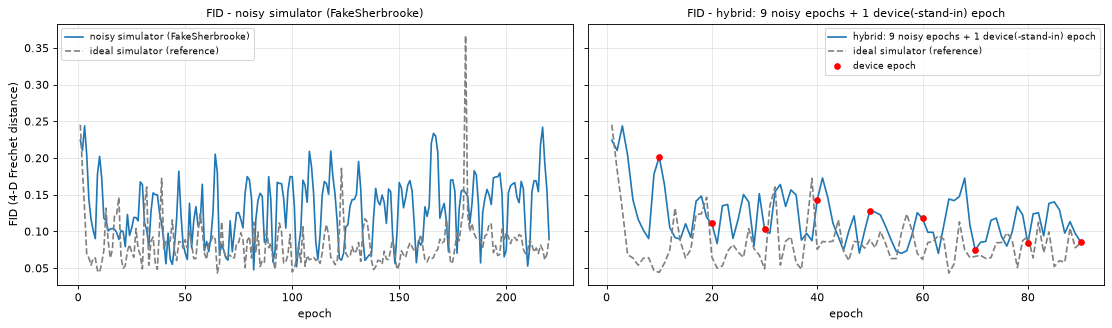

In [24]:
def hist_of(name):
    hs = [v["hist"].set_index("epoch") for (n_, s_), v in RUNS.items() if n_ == name]
    return pd.concat(hs).groupby(level=0).mean(numeric_only=True) if hs else None

NAMES = {"ideal": "Ideal simulator", "noisy": "Noisy simulator FakeSherbrooke", "hybrid": "Hybrid (noisy + device epochs)"}
def two_panel(col, ylabel, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    hi, hn, hh = hist_of(NAMES["ideal"]), hist_of(NAMES["noisy"]), hist_of(NAMES["hybrid"])
    for a, h, nm_ in [(ax[0], hn, "noisy simulator (FakeSherbrooke)"), (ax[1], hh, "hybrid: 9 noisy epochs + 1 device(-stand-in) epoch")]:
        hi_ = hi.loc[hi.index <= h.index.max()]
        a.plot(h.index, h[col], color="C0", label=nm_); a.plot(hi_.index, hi_[col], "--", color="gray", label="ideal simulator (reference)")
        a.set_title(title + " - " + nm_, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=8)
    dev = hh.index[(hh.index % HYBRID_PERIOD) == 0]
    ax[1].scatter(dev, hh.loc[dev, col], color="red", zorder=5, s=25, label="device epoch"); ax[1].legend(fontsize=8)
    ax[0].set_ylabel(ylabel); plt.tight_layout(); plt.show()
two_panel("fid", "FID (4-D Frechet distance)", "FID")

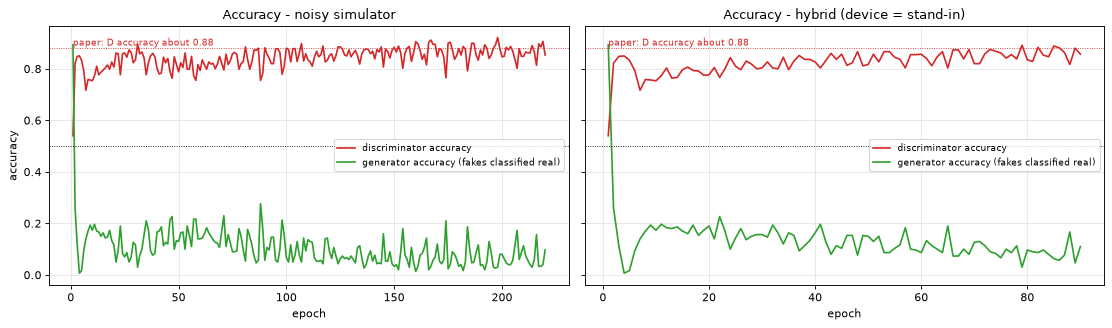

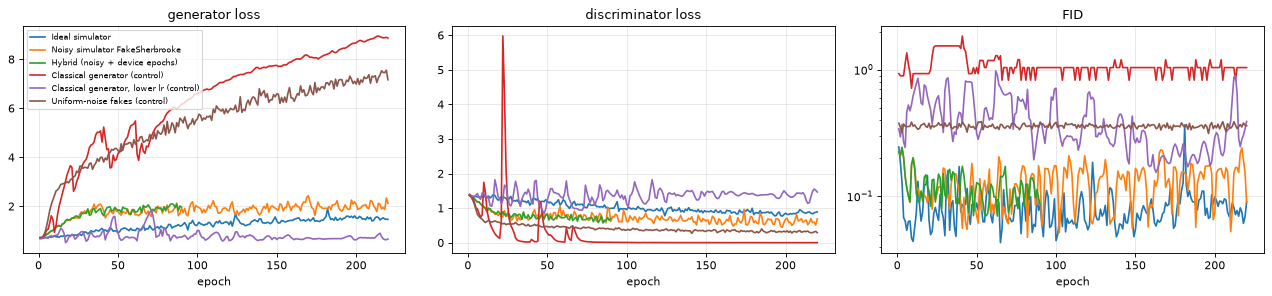

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, nm_, ttl in [(ax[0], NAMES["noisy"], "noisy simulator"), (ax[1], NAMES["hybrid"], "hybrid (device = stand-in)")]:
    h = hist_of(nm_)
    a.plot(h.index, h.acc_D, color="C3", label="discriminator accuracy"); a.plot(h.index, h.acc_G, color="C2", label="generator accuracy (fakes classified real)")
    a.axhline(0.5, color="k", ls=":", lw=0.8); a.axhline(PAPER["d_acc"], color="C3", ls=":", lw=0.8)
    a.text(h.index[0], PAPER["d_acc"] + 0.01, "paper: D accuracy about 0.88", fontsize=8, color="C3")
    a.set_title("Accuracy - " + ttl); a.set_xlabel("epoch"); a.legend(fontsize=8, loc="center right")
ax[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for nm_ in list(NAMES.values()) + ["Classical generator (control)", "Classical generator, lower lr (control)", "Uniform-noise fakes (control)"]:
    h = hist_of(nm_)
    if h is None: continue
    ax[0].plot(h.index, h.loss_G, label=nm_); ax[1].plot(h.index, h.loss_D, label=nm_); ax[2].plot(h.index, h.fid, label=nm_)
for a, t_ in zip(ax, ["generator loss", "discriminator loss", "FID"]):
    a.set_title(t_); a.set_xlabel("epoch")
ax[2].set_yscale("log"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [26]:
def tail_mean(h, col, k):
    return float(h[col].tail(k).mean())
rows = []
for nm_ in [n for n in dict.fromkeys(k[0] for k in RUNS)]:
    h = hist_of(nm_); E = len(h); k = max(3, min(10, E // 5))
    secs = np.mean([v["secs"] for (n_, s_), v in RUNS.items() if n_ == nm_])
    rows.append({"run": nm_, "epochs": E, "seeds": sum(1 for kk in RUNS if kk[0] == nm_), "FID first 3 epochs": h.fid.head(3).mean(), "k (last epochs averaged)": k, "FID last k": tail_mean(h, "fid", k),
                 "D acc last k": tail_mean(h, "acc_D", k), "G acc last k": tail_mean(h, "acc_G", k), "G acc mean (first 100 epochs)": float(h.acc_G.head(100).mean()), "CPU s per epoch": secs / E})
SUMMARY = pd.DataFrame(rows).set_index("run"); display(SUMMARY.round(4))

,epochs,seeds,FID first 3 epochs,k (last epochs averaged),FID last k,D acc last k,G acc last k,G acc mean (first 100 epochs),CPU s per epoch
run,,,,,,,,,
Ideal simulator,220,3,0.1863,10,0.0767,0.8088,0.1409,0.3083,1.0963
Noisy simulator FakeSherbrooke,220,1,0.2261,10,0.1625,0.8700,0.0620,0.1396,3.0915
Hybrid (noisy + device epochs),90,1,0.2261,10,0.1144,0.8598,0.0873,0.1351,3.2116
Classical generator (control),220,3,0.9082,10,1.0194,1.0000,0.0000,0.0531,0.1118
"Classical generator, lower lr (control)",220,3,0.3355,10,0.4882,0.5562,0.3947,0.3598,0.1074
Uniform-noise fakes (control),220,3,0.3496,10,0.3640,0.9403,0.0806,0.1352,0.0906
"Noisy, reverse_linear entanglement (ablation)",220,1,0.2292,10,0.0864,0.8202,0.1640,0.3664,1.2312


### 5.1 What the generators learned: real versus generated samples

Real benign flows (grey) and the samples of each trained generator for the same 1000 latent vectors, in the 4-D [0, 1] feature space (features 1 and 2 on the left, 3 and 4 on the right). A generator that has learned the benign distribution puts its points where the grey cloud is dense.

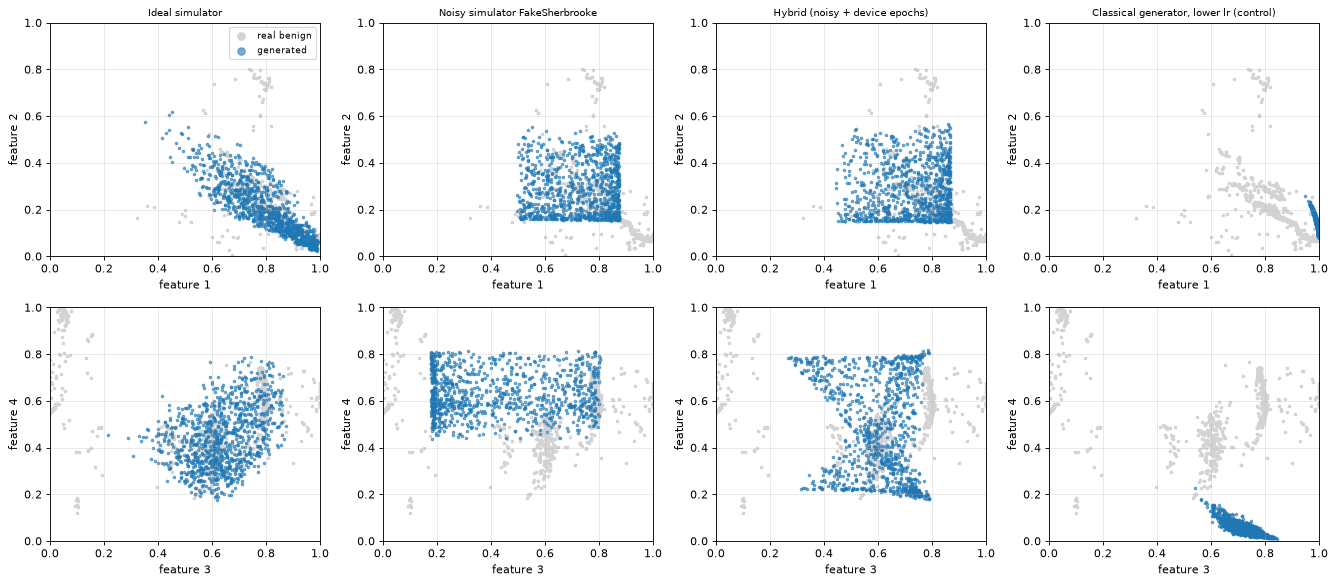

In [27]:
show = [n for n in list(NAMES.values()) + ["Classical generator, lower lr (control)"] if any(k[0] == n for k in RUNS)]
fig, ax = plt.subplots(2, len(show), figsize=(4.2 * len(show), 7.4), squeeze=False)
real = U["benval"]
for j, nm_ in enumerate(show):
    gen = [v for (n_, s_), v in RUNS.items() if n_ == nm_][0]["gen"]; G_ = generated(gen, Z_VIS)
    for i, (a_, b_) in enumerate([(0, 1), (2, 3)]):
        ax[i, j].scatter(real[:, a_], real[:, b_], s=5, color="lightgray", label="real benign")
        ax[i, j].scatter(G_[:, a_], G_[:, b_], s=5, color="C0", alpha=0.6, label="generated")
        ax[i, j].set_xlim(0, 1); ax[i, j].set_ylim(0, 1); ax[i, j].set_xlabel(f"feature {a_ + 1}"); ax[i, j].set_ylabel(f"feature {b_ + 1}")
    ax[0, j].set_title(nm_, fontsize=9)
ax[0, 0].legend(markerscale=3, fontsize=8); plt.tight_layout(); plt.show()

## 6. Extra (not in the paper): do the trained discriminators detect attacks?

The paper's title says *intrusion detection*, but it reports only FID and accuracies on real/fake samples, no detection score. For completeness this section uses each trained discriminator as an anomaly detector: a flow whose discriminator score `D(x)` falls below the **5 % quantile of `D` on held-out benign flows** is flagged as an attack (no attack label is used to set the threshold). Classical detectors on exactly the same four features are shown next to them: `IsolationForest` and `OneClassSVM` (benign flows only, like the GAN) and, as supervised upper references that do see attack labels, `RandomForest` and `SVC(rbf)`. Metrics: accuracy, F1 (attack = positive class) and ROC AUC on the 20 % hold-out of `KDDTrain+` and on `KDDTest+`.

In [28]:
def detect_metrics(score_fn, name):
    thr = np.quantile(score_fn(U["benval"]), BENIGN_FPR); out = {"detector": name}
    for tag, key in [("hold-out", "ho"), ("KDDTest+", "kddtest")]:
        s = score_fn(U[key]); y = Y[key]; pred = (s < thr).astype(int)
        out.update({f"acc {tag}": accuracy_score(y, pred), f"F1 {tag}": f1_score(y, pred), f"AUC {tag}": roc_auc_score(y, -s)})
    return out

def d_score(D):
    return lambda X: D(torch.as_tensor(X)).squeeze(1).detach().numpy()

rows = []
for nm_ in dict.fromkeys(k[0] for k in RUNS):
    per = [detect_metrics(d_score(v["D"]), "D of: " + nm_) for (n_, s_), v in RUNS.items() if n_ == nm_]
    rows.append(pd.DataFrame(per).drop(columns="detector").mean().to_frame().T.assign(detector="D of: " + nm_ + f" (mean of {len(per)})"))
Xp = U["pool"][np.random.default_rng(SEED).choice(len(U["pool"]), 4000, replace=False)]
iso = IsolationForest(random_state=SEED, n_estimators=200).fit(Xp)
ocs = OneClassSVM(gamma="scale", nu=0.05).fit(Xp[:2500])
rows.append(pd.DataFrame([detect_metrics(lambda X: iso.decision_function(X), "IsolationForest (benign only)")]))
rows.append(pd.DataFrame([detect_metrics(lambda X: ocs.decision_function(X), "OneClassSVM rbf (benign only)")]))
# supervised references: 6000 labelled flows of the training split, same 4 features, natural 0.5 threshold
sl = np.random.default_rng(SEED).choice(len(TR_ALL), 6000, replace=False)
for name, clf in [("RandomForest (supervised)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)), ("SVC rbf (supervised)", SVC(kernel="rbf", C=1.0, random_state=SEED))]:
    clf.fit(U["train"][sl], Y["train"][sl]); o = {"detector": name}
    for tag, key in [("hold-out", "ho"), ("KDDTest+", "kddtest")]:
        pred = clf.predict(U[key]); sc = clf.predict_proba(U[key])[:, 1] if hasattr(clf, "predict_proba") else clf.decision_function(U[key])
        o.update({f"acc {tag}": accuracy_score(Y[key], pred), f"F1 {tag}": f1_score(Y[key], pred), f"AUC {tag}": roc_auc_score(Y[key], sc)})
    rows.append(pd.DataFrame([o]))
DETECT = pd.concat(rows, ignore_index=True).set_index("detector")
for tag, key in [("hold-out", "ho"), ("KDDTest+", "kddtest")]:
    print(f"all-normal predictor accuracy on {tag}: {1 - Y[key].mean():.3f} (attack share {Y[key].mean():.3f})")
display(DETECT.round(3))

all-normal predictor accuracy on hold-out: 0.535 (attack share 0.465)
all-normal predictor accuracy on KDDTest+: 0.431 (attack share 0.569)


,acc hold-out,F1 hold-out,AUC hold-out,acc KDDTest+,F1 KDDTest+,AUC KDDTest+
detector,,,,,,
D of: Ideal simulator (mean of 3),0.804,0.748,0.803,0.584,0.435,0.695
D of: Noisy simulator FakeSherbrooke (mean of 1),0.773,0.700,0.864,0.525,0.320,0.823
D of: Hybrid (noisy + device epochs) (mean of 1),0.792,0.731,0.928,0.558,0.396,0.912
D of: Classical generator (control) (mean of 3),0.830,0.791,0.811,0.545,0.351,0.557
"D of: Classical generator, lower lr (control) (mean of 3)",0.552,0.145,0.423,0.505,0.218,0.509
D of: Uniform-noise fakes (control) (mean of 3),0.926,0.918,0.974,0.801,0.793,0.935
"D of: Noisy, reverse_linear entanglement (ablation) (mean of 1)",0.843,0.811,0.945,0.631,0.535,0.902
IsolationForest (benign only),0.922,0.914,0.966,0.782,0.769,0.931
OneClassSVM rbf (benign only),0.914,0.906,0.917,0.748,0.727,0.661


**How to read this table.** The unsupervised detectors (discriminators, `IsolationForest`, `OneClassSVM`) are on the same footing: they see benign flows only. The discriminator of a GAN whose "fakes" are meaningless uniform noise is a useful control: if it detects attacks as well as the discriminators of the quantum GANs, the quantum generator is not what makes the detection work. Supervised models, which see labels, show what the four PCA features allow at best.

## 7. Real-device cells (only with `IBM_TOKEN`)

With a (free-tier) IBM Quantum API key in `IBM_TOKEN`, the next cell samples the **trained noisy-run generator** on the real `IBM_BACKEND` for a few latent vectors and compares the device's marginals with the ideal and with the `FakeSherbrooke` simulation. This is the single measurement the notebook can make on hardware without hundreds of device-minutes. It is **not executed in the published notebook** (no token was used), so no device number below comes from this notebook; the code path is untested. Full hardware-in-the-loop training is available through `USE_IBM_IN_TRAINING = True` and would need many hours of device time.

In [29]:
HARDWARE = None
if IBM_TOKEN:
    try:
        gen_n = [v for (n_, s_), v in RUNS.items() if n_ == NAMES["noisy"]][0]["gen"]
        Zd = Z_VIS[:20]
        t0 = time.time(); dev_m = ibm_marginals(gen_n.theta.detach().double().numpy(), Zd.numpy())
        sim_m = generated(gen_n, Zd)
        ide = IdealGenerator(init_seed=0); ide.theta.data = gen_n.theta.detach().double().clone()
        ide_m = generated(ide, Zd)
        HARDWARE = dict(dev_vs_noisysim=float(np.abs(dev_m - sim_m).mean()), dev_vs_ideal=float(np.abs(dev_m - ide_m).mean()), noisysim_vs_ideal=float(np.abs(sim_m - ide_m).mean()))
        print(f"{IBM_BACKEND}: {len(Zd)} latent vectors in {time.time() - t0:.0f} s | mean |marginal difference| device vs noisy simulation {HARDWARE['dev_vs_noisysim']:.3f}, "
              f"device vs ideal {HARDWARE['dev_vs_ideal']:.3f}, noisy simulation vs ideal {HARDWARE['noisysim_vs_ideal']:.3f}")
    except Exception as e:
        print("real-device cell failed (needs a valid IBM_TOKEN and an available backend):", repr(e)[:200])
else:
    print("IBM_TOKEN is empty: real-device cells are skipped. The hybrid run above used the finite-shot stand-in for its device epochs.")

IBM_TOKEN is empty: real-device cells are skipped. The hybrid run above used the finite-shot stand-in for its device epochs.


## 8. Side-by-side comparison with the paper

The paper reports its results as plots (Figures 2 and 3) and in the text; there is no table of numbers. The values below are the ones stated in the text. A claim is **reproduced** when the notebook is within 0.02 of the stated value (accuracy / explained variance) or shows the stated behaviour; **not reached** / **exceeded** gives the gap; **cannot be checked** when the check needs the real device or the authors' cost data. The notebook's numbers are averages over the last epochs of the run (see the summary table in Section 5) and, where several seeds were run, over seeds.

In [30]:
def verdict(val, target, tol=TOL_ACC):
    gap = val - target
    return "reproduced" if abs(gap) <= tol else (f"not reached (gap {gap:+.3f})" if gap < 0 else f"exceeded (gap {gap:+.3f})")

nm_n, nm_h = NAMES["noisy"], NAMES["hybrid"]
hn, hh, hi = hist_of(nm_n), hist_of(nm_h), hist_of(NAMES["ideal"])
kn, kh = max(3, min(10, len(hn) // 5)), max(3, min(10, len(hh) // 5))
Eh = len(hh)
fid_first_n, fid_last_n = hn.fid.head(3).mean(), hn.fid.tail(kn).mean()
fid_first_h, fid_last_h = hh.fid.head(3).mean(), hh.fid.tail(kh).mean()
fid_n_same = hn.fid.iloc[Eh - kh:Eh].mean()                                      # noisy run at the same epochs as the last epochs of the hybrid run
rel_fid = abs(fid_last_h - fid_n_same) / max(fid_last_h, fid_n_same)
d_n, d_h = hn.acc_D.tail(kn).mean(), hh.acc_D.tail(kh).mean()
g_n, g_h = hn.acc_G.head(100).mean(), hh.acc_G.head(100).mean()
d_n_same = hn.acc_D.iloc[Eh - kh:Eh].mean()

CLAIMS = pd.DataFrame([
    ["PCA explained variance of the 4 components", "0.71", f"{EV:.3f}", verdict(EV, PAPER["explained_variance"])],
    ["FID decreases over the epochs, noisy simulator", "decreases (Fig. 2)", f"{fid_first_n:.4f} -> {fid_last_n:.4f}", "reproduced" if fid_last_n < fid_first_n else "not reached"],
    ["FID decreases over the epochs, hybrid run", "decreases (Fig. 2)", f"{fid_first_h:.4f} -> {fid_last_h:.4f}", "reproduced" if fid_last_h < fid_first_h else "not reached"],
    ["Hybrid and simulator FID alike (same epochs)", "no substantial difference", f"noisy {fid_n_same:.4f} vs hybrid {fid_last_h:.4f} (relative gap {rel_fid:.2f}; same seed and initialisation, so only the device epochs can make them differ)", "reproduced" if rel_fid <= 0.25 else f"not reached (relative gap {rel_fid:.2f} > 0.25)"],
    ["Noisy emulator costs little compared with ideal simulation (paper conclusion: minimal impact)", "minimal impact of noise", f"FID ideal {hi.fid.tail(kn).mean():.4f} vs noisy {fid_last_n:.4f}; D acc ideal {hi.acc_D.tail(kn).mean():.3f} vs noisy {d_n:.3f}", "reproduced" if abs(fid_last_n - hi.fid.tail(kn).mean()) / max(fid_last_n, hi.fid.tail(kn).mean()) <= 0.25 and abs(d_n - hi.acc_D.tail(kn).mean()) <= TOL_ACC else f"not reached (noise raises the FID by a factor {fid_last_n / hi.fid.tail(kn).mean():.1f})"],
    ["Generator accuracy about 0.5 in the first 100 epochs, noisy simulator", "about 0.5 (Fig. 3)", f"{g_n:.3f} (mean of epochs 1-{min(100, len(hn))})", "reproduced" if abs(g_n - 0.5) <= 0.10 else f"not reached (gap {g_n - 0.5:+.3f})"],
    ["Generator accuracy about 0.5 in the first 100 epochs, hybrid", "about 0.5 (Fig. 3)", f"{g_h:.3f} (mean of epochs 1-{min(100, Eh)})", "reproduced" if abs(g_h - 0.5) <= 0.10 else f"not reached (gap {g_h - 0.5:+.3f})"],
    ["Discriminator accuracy at the end, noisy simulator", "about 0.88", f"{d_n:.3f} (last {kn} epochs, {len(hn)} epochs run)", verdict(d_n, PAPER["d_acc"])],
    ["Discriminator accuracy at the end, hybrid", "about 0.88", f"{d_h:.3f} (last {kh} epochs, {Eh} epochs run)", verdict(d_h, PAPER["d_acc"])],
    ["Hybrid and simulator discriminator accuracy alike (same epochs)", "alike (Fig. 3)", f"noisy {d_n_same:.3f} vs hybrid {d_h:.3f}", "reproduced" if abs(d_n_same - d_h) <= TOL_ACC else f"not reached (gap {d_h - d_n_same:+.3f})"],
    ["Simulation consistent with the real IBM Sherbrooke device", "minimal loss on hardware", "no device run (IBM_TOKEN empty)" if HARDWARE is None else f"device vs noisy-sim marginals differ by {HARDWARE['dev_vs_noisysim']:.3f}", "cannot be checked" if HARDWARE is None else "see Section 7"],
    ["Device time (1-1.5 s per circuit) and cost (24k USD) estimates", "1-1.5 s per circuit; 24k USD", "not measurable here", "cannot be checked"],
], columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 220)
display(CLAIMS)

,Claim,Paper,This notebook,Verdict
0,PCA explained variance of the 4 components,0.71,0.729,reproduced
1,"FID decreases over the epochs, noisy simulator",decreases (Fig. 2),0.2261 -> 0.1625,reproduced
2,"FID decreases over the epochs, hybrid run",decreases (Fig. 2),0.2261 -> 0.1144,reproduced
3,Hybrid and simulator FID alike (same epochs),no substantial difference,"noisy 0.1239 vs hybrid 0.1144 (relative gap 0.08; same seed and initialisation, so only the device epochs can make t...",reproduced
4,Noisy emulator costs little compared with ideal simulation (paper conclusion: minimal impact),minimal impact of noise,FID ideal 0.0767 vs noisy 0.1625; D acc ideal 0.809 vs noisy 0.870,not reached (noise raises the FID by a factor 2.1)
5,"Generator accuracy about 0.5 in the first 100 epochs, noisy simulator",about 0.5 (Fig. 3),0.140 (mean of epochs 1-100),not reached (gap -0.360)
6,"Generator accuracy about 0.5 in the first 100 epochs, hybrid",about 0.5 (Fig. 3),0.135 (mean of epochs 1-90),not reached (gap -0.365)
7,"Discriminator accuracy at the end, noisy simulator",about 0.88,"0.870 (last 10 epochs, 220 epochs run)",reproduced
8,"Discriminator accuracy at the end, hybrid",about 0.88,"0.860 (last 10 epochs, 90 epochs run)",not reached (gap -0.020)
9,Hybrid and simulator discriminator accuracy alike (same epochs),alike (Fig. 3),noisy 0.839 vs hybrid 0.860,not reached (gap +0.021)


In [31]:
def seed_spread(name, col, k):
    vals = [v["hist"][col].tail(k).mean() for (n_, s_), v in RUNS.items() if n_ == name]
    return (float(np.mean(vals)), float(np.std(vals)), len(vals))

fi, fn_, fh_ = hi.fid.tail(kn).mean(), fid_last_n, fid_last_h
print("READING OF THIS RUN (numbers are computed from the runs above)")
print(f"* FID (lower is better), mean of the last {kn} epochs: ideal simulator {fi:.4f} | noisy FakeSherbrooke {fn_:.4f} | hybrid {fh_:.4f} (last {kh} epochs of {Eh}); first 3 epochs: ideal {hi.fid.head(3).mean():.4f}, noisy {fid_first_n:.4f}.")
verdict_noise = "not what this simulation shows for this circuit (the paper claims a minimal impact of noise)" if fn_ / fi > 1.25 else "consistent with a small effect of noise"
print(f"  -> the noisy circuit FID is {fn_ / fi:.1f} times the ideal one: {verdict_noise}.")
print(f"* Discriminator accuracy (last epochs): ideal {hi.acc_D.tail(kn).mean():.3f} | noisy {d_n:.3f} | hybrid {d_h:.3f} (paper: about {PAPER['d_acc']}); generator accuracy: ideal {hi.acc_G.tail(kn).mean():.3f} | noisy {hn.acc_G.tail(kn).mean():.3f} | hybrid {hh.acc_G.tail(kh).mean():.3f}.")
print("  -> a discriminator accuracy near 0.5 means the generator fools it; the closer to 1, the worse the generator. Closest to 0.5 here: " + min([("ideal simulator", hi.acc_D.tail(kn).mean()), ("noisy simulator", d_n), ("hybrid", d_h)], key=lambda t: abs(t[1] - 0.5))[0] + ".")
gap = np.abs(hh.fid.values - hn.fid.values[:Eh]) / np.maximum(hh.fid.values, hn.fid.values[:Eh])
print(f"* Hybrid versus noisy run, same epochs: mean relative FID difference {gap.mean():.3f}, largest {gap.max():.3f} (first device epoch is epoch {HYBRID_PERIOD}; before it the two runs are identical by construction).")
for nm_ in [NAMES["ideal"], NAMES["noisy"]]:
    m_, s_, n_ = seed_spread(nm_, "fid", kn if nm_ == NAMES["ideal"] else kn)
    if n_ > 1:
        print(f"* seed-to-seed spread of the final FID, {nm_}: {m_:.4f} +/- {s_:.4f} over {n_} seeds (compare with the noisy-vs-hybrid difference above).")
def _auc(det, col):
    r = DETECT.loc[[i for i in DETECT.index if i.startswith(det)]]
    return float(r[col].iloc[0]) if len(r) else float("nan")
print(f"* Extra detection experiment, AUC on KDDTest+: discriminator of the quantum GAN (noisy) {_auc('D of: Noisy', 'AUC KDDTest+'):.3f}, ideal {_auc('D of: Ideal', 'AUC KDDTest+'):.3f}, uniform-noise control {_auc('D of: Uniform', 'AUC KDDTest+'):.3f}, "
      f"IsolationForest {_auc('IsolationForest', 'AUC KDDTest+'):.3f}, supervised RandomForest {_auc('RandomForest', 'AUC KDDTest+'):.3f}.")
auc_q, auc_u = _auc("D of: Noisy", "AUC KDDTest+"), _auc("D of: Uniform", "AUC KDDTest+")
print("  -> " + ("a discriminator trained against plain uniform noise detects attacks about as well (within 0.03 AUC), so the detection ability does not come from the quantum generator." if abs(auc_q - auc_u) <= 0.03 else "the discriminator of the quantum GAN and the uniform-noise control differ by more than 0.03 AUC; see the table."))

READING OF THIS RUN (numbers are computed from the runs above)
* FID (lower is better), mean of the last 10 epochs: ideal simulator 0.0767 | noisy FakeSherbrooke 0.1625 | hybrid 0.1144 (last 10 epochs of 90); first 3 epochs: ideal 0.1863, noisy 0.2261.
  -> the noisy circuit FID is 2.1 times the ideal one: not what this simulation shows for this circuit (the paper claims a minimal impact of noise).
* Discriminator accuracy (last epochs): ideal 0.809 | noisy 0.870 | hybrid 0.860 (paper: about 0.88); generator accuracy: ideal 0.141 | noisy 0.062 | hybrid 0.087.
  -> a discriminator accuracy near 0.5 means the generator fools it; the closer to 1, the worse the generator. Closest to 0.5 here: ideal simulator.
* Hybrid versus noisy run, same epochs: mean relative FID difference 0.232, largest 0.677 (first device epoch is epoch 10; before it the two runs are identical by construction).
* seed-to-seed spread of the final FID, Ideal simulator: 0.0767 +/- 0.0065 over 3 seeds (compare with the n

### Notes on the outputs stored in this file (full run, `FAST_MODE = False`)

These notes describe the executed run above (seeds 42, 43, 44 for the ideal and the control runs, seed 42 for the noisy-circuit runs, 100 minutes on a shared CPU); a re-run reproduces the code path and, because every seed is fixed, the numbers, up to floating-point differences between machines.

* **PCA.** The explained variance of the four components is 0.729 against the paper's 0.71: reproduced within 0.02.
* **FID falls, but not steadily.** All runs start at an FID of 0.19-0.23 and fall within the first 20 epochs; after that the curves oscillate between about 0.05 and 0.20 (the noisy run) or 0.05 and 0.12 (the ideal runs) with occasional spikes. The "decreases" verdict compares the first three epochs with the mean of the last ten; the paper's curves are described as steadily improving, which is a smoother picture than this notebook's. The last-ten mean of a single oscillating run is a noisy estimate, so the 2.1-fold ratio between the noisy and the ideal FID should be read as "clearly above" (the ideal simulator's seed-to-seed spread is about 8 %), not as a precise factor.
* **Discriminator accuracy.** After 220 epochs the noisy-simulator discriminator reaches 0.870 against the paper's 0.88 (reproduced), the hybrid run 0.860 after 90 epochs (0.02 below); the shape of the curves (a quick jump above 0.7 and a slow rise towards 0.88) resembles the paper's Figure 3. **Generator accuracy** (the share of fakes classified real) is about 0.14 in the first 100 epochs for the noisy run, not the paper's 0.5; the paper does not define the metric, so a different definition may explain the gap.
* **Noise is not "minimal" here.** With the paper's `circular` entanglement the compiled circuit has 64 `ecr` gates and the noisy FID is about twice the ideal one. The ablation with Qiskit's default `reverse_linear` entanglement (12 `ecr` gates) ends at an FID of 0.086 against 0.077 for the ideal simulator, i.e. noise is nearly harmless for the shallower circuit. The paper's conclusion therefore depends on the compiled circuit, which the paper does not report.
* **Hybrid versus noisy.** The two runs are identical up to the first device epoch and then drift apart: the mean relative FID difference over the first 90 epochs is 0.23, the last-ten means are 0.114 (hybrid) and 0.124 (noisy, same epochs), and the discriminator accuracies differ by 0.02. This is the size of ordinary GAN run-to-run variation and says nothing about a real device, because the stand-in device epoch is the same simulator with shot noise.
* **Detection (extra).** Used as anomaly detectors on `KDDTest+`, the discriminators of the quantum GANs reach AUC 0.70 (ideal, mean of 3 seeds), 0.82 (noisy), 0.91 (hybrid) and 0.90 (`reverse_linear`), while a discriminator trained against uniform noise reaches 0.935, `IsolationForest` 0.931 and the supervised random forest 0.936 on the same four features. A better generator does not make a better detector here.
* **Not checkable here.** Everything that needs the real Sherbrooke device (the paper's headline) and the cost / time estimates.

## 9. Reading the paper critically

* **What the paper can and cannot show.** The headline claim is that a QGAN trained partly on a real IBM device behaves like one trained on its noisy emulator. The evidence is two curves per figure from one run each, with no seeds, no confidence band and no table. Two GAN runs from the same initialisation can already differ by more than the difference between "emulator" and "emulator plus one device epoch in ten", and the device only enters one epoch in ten of a generator whose parameters are then updated from emulator gradients for the next nine; the hybrid run is thus much closer to the emulator run than to "training on hardware" by construction. A fair test of the claim needs several seeds and the same number of epochs for both settings (the paper has 220 versus 90).
* **The emulator is the whole story here.** `FakeSherbrooke` uses a frozen calibration snapshot. The notebook shows how much of a random generator's output the circuit's noise removes (the total-variation distance in the Quantum Circuit Architecture section) and that the compiled circuit needs four times as many two-qubit gates (64) as the logical one (16) because `circular` entanglement does not fit a line of qubits. The paper's own sentence that "the circuit is intentionally simple to enable execution on real hardware" holds for the logical circuit, not for the compiled one.
* **What "FID" means.** The Frechet *Inception* Distance is defined with features of an image network. For 4-D tabular features it can only be the plain Frechet distance between two fitted Gaussians (this notebook's choice); the paper does not say which features it used, so its curves cannot be compared numerically with the ones here, only in shape. A four-dimensional Gaussian summary also cannot see whether the generator reproduces the non-Gaussian, multi-modal shape of the benign traffic (Section 5.1 shows the scatter plots).
* **Discriminator accuracy of 0.88 is not a quality score.** In a GAN a high discriminator accuracy means the discriminator wins, i.e. the generator is *not* fooling it. The paper presents 0.88 as acceptable ("modest") rather than as a sign of success; the notebook reports it because the paper does, together with the generator accuracy, and the controls (a classical generator, uniform noise as fakes) show how much the 40-parameter quantum generator adds.
* **No intrusion-detection result.** Despite the title, the paper never uses the trained model to classify a flow, so detection performance is untested. Section 6 adds a detection experiment; compare it with the unsupervised and supervised classical baselines before concluding anything about a quantum advantage.
* **Four principal components.** The explained variance (0.71 in the paper, about 0.73 here) leaves a quarter of the variance out, and `U2R` / `R2L` attacks overlap with benign traffic in these four coordinates, so even a perfect benign model cannot separate them.
* **Cost argument.** The 24k USD estimate assumes training from scratch on the device for 220 epochs at 48 USD per minute; it depends on the pricing and on the epoch count, neither of which this notebook can test.

## 10. Exercises

1. **Seeds.** Set `SEEDS_NOISY = [42, 43, 44, 45, 46]` (full mode) and compare the spread of the final FID between seeds of the *same* setting with the difference between the noisy and the hybrid run. Is the paper's "no substantial difference" larger than the seed-to-seed noise?
2. **Entanglement.** Train the noisy run with `ENTANGLEMENT = "reverse_linear"` (the ablation of Section 4) and with `"linear"`; the compiled circuit has fewer than a fifth of the two-qubit gates. Does the FID of the noisy simulation move towards the ideal one?
3. **Other devices.** Replace `FakeSherbrooke` by another fake backend of `qiskit_ibm_runtime.fake_provider` (for instance `FakeKyiv` or `FakeBrisbane`) and let `best_line` choose the qubits. Which noise source (two-qubit gate, relaxation, read-out) matters most? Hint: build `NoiseModel.from_backend(backend, thermal_relaxation=False)` or switch off the read-out error in `NoisyGenerator`.
4. **Device epochs.** Change `HYBRID_PERIOD` to 2 and then to 1000. How does the FID curve of the "hybrid" run change? With a finite-shot stand-in, what in the hybrid run is actually different from the noisy run, and what would a real device change?
5. **Detection.** Use the real-versus-generated *probabilities* of the discriminator as an anomaly score for `KDDTest+` per attack family (`FAMS["kddtest"]`). Which families does the discriminator miss, and does that agree with what the PCA scatter plot of Section 2 suggests?